# **PHASE 1: PROJECT SETUP**

In [1]:
# ============================================================
# PHASE 1.1: IMPORT LIBRARIES AND CONFIGURE ENVIRONMENT
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

# Machine learning models
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


In [2]:
# ============================================================
# PHASE 1.2: UPLOAD AND LOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

df_raw = pd.read_csv("results.csv")

print("DATASET LOADED SUCCESSFULLY")
print("-" * 40)

print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]}")

Saving results.csv to results.csv
DATASET LOADED SUCCESSFULLY
----------------------------------------
Rows    : 49,502
Columns : 9


In [3]:
# ============================================================
# PHASE 1.3: PRESERVE RAW DATASET
# ============================================================

# Preserve the original dataset for before-and-after comparison
df = df_raw.copy()

print("RAW DATASET PRESERVATION")
print("-" * 40)

print("A working copy of the raw dataset has been created.")
print("df_raw : Original dataset")
print("df     : Working dataset")

RAW DATASET PRESERVATION
----------------------------------------
A working copy of the raw dataset has been created.
df_raw : Original dataset
df     : Working dataset


# **PHASE 2: INITIAL DATA AUDIT**

In [4]:
# ============================================================
# PHASE 2.1: PREVIEW DATASET AND INSPECT STRUCTURE
# ============================================================

print("FIRST FIVE ROWS OF THE DATASET")
print("-" * 40)

display(df.head())


print("\nDATASET DIMENSIONS")
print("-" * 40)

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")


print("\nDATASET INFORMATION")
print("-" * 40)

df.info()

FIRST FIVE ROWS OF THE DATASET
----------------------------------------


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2.0,2.0,Friendly,London,England,False
4,1876-03-04,Scotland,England,3.0,0.0,Friendly,Glasgow,Scotland,False



DATASET DIMENSIONS
----------------------------------------
Rows    : 49,502
Columns : 9

DATASET INFORMATION
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49502 entries, 0 to 49501
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        49502 non-null  object 
 1   home_team   49502 non-null  object 
 2   away_team   49502 non-null  object 
 3   home_score  49495 non-null  float64
 4   away_score  49495 non-null  float64
 5   tournament  49502 non-null  object 
 6   city        49502 non-null  object 
 7   country     49502 non-null  object 
 8   neutral     49502 non-null  bool   
dtypes: bool(1), float64(2), object(6)
memory usage: 3.1+ MB


In [5]:
# ============================================================
# PHASE 2.2: AUDIT MISSING VALUES
# ============================================================

# Check missing values
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),

    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(4)
})

print("MISSING VALUE AUDIT")
print("-" * 40)

display(missing_values)

MISSING VALUE AUDIT
----------------------------------------


,Missing Count,Missing Percentage (%)
date,0,0.0000
home_team,0,0.0000
away_team,0,0.0000
home_score,7,0.0141
away_score,7,0.0141
tournament,0,0.0000
city,0,0.0000
country,0,0.0000
neutral,0,0.0000


In [6]:
# ============================================================
# PHASE 2.3: AUDIT DUPLICATE RECORDS
# ============================================================

duplicate_count = df.duplicated().sum()

print("DUPLICATE RECORD AUDIT")
print("-" * 40)

print(f"Exact duplicate rows: {duplicate_count}")

DUPLICATE RECORD AUDIT
----------------------------------------
Exact duplicate rows: 0


In [7]:
# ============================================================
# PHASE 2.4: AUDIT DATE RANGE AND DATE VALIDITY
# ============================================================

# Temporary date conversion for audit purposes
date_check = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("DATE RANGE")
print("-" * 40)

print(
    f"Earliest match : "
    f"{date_check.min()}"
)

print(
    f"Latest match   : "
    f"{date_check.max()}"
)

print(
    f"Invalid dates  : "
    f"{date_check.isnull().sum()}"
)

DATE RANGE
----------------------------------------
Earliest match : 1872-11-30 00:00:00
Latest match   : 2026-07-09 00:00:00
Invalid dates  : 0


In [8]:
# ============================================================
# PHASE 2.5: SUMMARISE UNIQUE VALUES
# ============================================================

print("UNIQUE VALUE SUMMARY")
print("-" * 40)

print(
    f"Unique home teams : "
    f"{df['home_team'].nunique():,}"
)

print(
    f"Unique away teams : "
    f"{df['away_team'].nunique():,}"
)

print(
    f"Unique tournaments: "
    f"{df['tournament'].nunique():,}"
)

print(
    f"Unique countries  : "
    f"{df['country'].nunique():,}"
)

print(
    f"Unique cities     : "
    f"{df['city'].nunique():,}"
)

UNIQUE VALUE SUMMARY
----------------------------------------
Unique home teams : 327
Unique away teams : 321
Unique tournaments: 200
Unique countries  : 269
Unique cities     : 2,089


In [9]:
# ============================================================
# PHASE 2.6: ANALYSE TOURNAMENT DISTRIBUTION
# ============================================================

print("TOP 20 TOURNAMENTS BY NUMBER OF MATCHES")
print("-" * 50)

tournament_counts = (
    df["tournament"]
    .value_counts()
    .head(20)
    .to_frame("Number of Matches")
)

display(tournament_counts)

TOP 20 TOURNAMENTS BY NUMBER OF MATCHES
--------------------------------------------------


,Number of Matches
tournament,
Friendly,18388
FIFA World Cup qualification,8771
UEFA Euro qualification,2824
African Cup of Nations qualification,2327
FIFA World Cup,1061
Copa América,869
African Cup of Nations,845
AFC Asian Cup qualification,829
UEFA Nations League,658


In [10]:
# ============================================================
# PHASE 2.7: ANALYSE FIFA WORLD CUP RECORDS
# ============================================================

world_cup_matches = df[
    df["tournament"] == "FIFA World Cup"
]

print("FIFA WORLD CUP MATCHES")
print("-" * 40)

print(
    f"Number of FIFA World Cup matches: "
    f"{len(world_cup_matches):,}"
)

display(
    world_cup_matches.head()
)

FIFA WORLD CUP MATCHES
----------------------------------------
Number of FIFA World Cup matches: 1,061


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
1490,1930-07-13,Belgium,United States,0.0,3.0,FIFA World Cup,Montevideo,Uruguay,True
1491,1930-07-13,France,Mexico,4.0,1.0,FIFA World Cup,Montevideo,Uruguay,True
1492,1930-07-14,Brazil,Yugoslavia,1.0,2.0,FIFA World Cup,Montevideo,Uruguay,True
1493,1930-07-14,Peru,Romania,1.0,3.0,FIFA World Cup,Montevideo,Uruguay,True
1494,1930-07-15,Argentina,France,1.0,0.0,FIFA World Cup,Montevideo,Uruguay,True


In [11]:
# ============================================================
# PHASE 2.8: INVESTIGATE MISSING SCORE RECORDS
# ============================================================

missing_score_matches = df[
    df["home_score"].isnull() |
    df["away_score"].isnull()
]

print("MATCHES WITH MISSING SCORES")
print("-" * 40)

print(
    f"Number of affected matches: "
    f"{len(missing_score_matches)}"
)

display(missing_score_matches)

MATCHES WITH MISSING SCORES
----------------------------------------
Number of affected matches: 7


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49495,2026-07-05,Brazil,Norway,NaN,NaN,FIFA World Cup,East Rutherford,United States,True
49496,2026-07-05,Mexico,England,NaN,NaN,FIFA World Cup,Mexico City,Mexico,False
49497,2026-07-06,Portugal,Spain,NaN,NaN,FIFA World Cup,Dallas,United States,True
49498,2026-07-06,United States,Belgium,NaN,NaN,FIFA World Cup,Seattle,United States,False
49499,2026-07-06,Argentina,Egypt,NaN,NaN,FIFA World Cup,Atlanta,United States,True
49500,2026-07-06,Switzerland,Colombia,NaN,NaN,FIFA World Cup,Vancouver,Canada,True
49501,2026-07-09,France,Morocco,NaN,NaN,FIFA World Cup,Foxborough,United States,True


# **PHASE 3: DATA CLEANING**

In [12]:
# ============================================================
# PHASE 3.1: CONVERT DATE DATA TYPE
# ============================================================

# Convert the date column from object to datetime
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("DATE TYPE CONVERSION")
print("-" * 40)

print(
    f"Data type before preprocessing : "
    f"{df_raw['date'].dtype}"
)

print(
    f"Data type after preprocessing  : "
    f"{df['date'].dtype}"
)

print(
    f"Invalid dates after conversion : "
    f"{df['date'].isnull().sum()}"
)

DATE TYPE CONVERSION
----------------------------------------
Data type before preprocessing : object
Data type after preprocessing  : datetime64[ns]
Invalid dates after conversion : 0


In [13]:
# ============================================================
# PHASE 3.2: SORT MATCHES CHRONOLOGICALLY
# ============================================================

# Sort all matches chronologically
df = (
    df
    .sort_values("date")
    .reset_index(drop=True)
)

print("CHRONOLOGICAL SORTING")
print("-" * 40)

print(
    f"First match date : "
    f"{df['date'].min().date()}"
)

print(
    f"Last match date  : "
    f"{df['date'].max().date()}"
)

print("\nFirst 3 records:")
display(df.head(3))

print("\nLast 3 records:")
display(df.tail(3))

CHRONOLOGICAL SORTING
----------------------------------------
First match date : 1872-11-30
Last match date  : 2026-07-09

First 3 records:


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0.0,0.0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4.0,2.0,Friendly,London,England,False
2,1874-03-07,Scotland,England,2.0,1.0,Friendly,Glasgow,Scotland,False



Last 3 records:


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49499,2026-07-06,Portugal,Spain,NaN,NaN,FIFA World Cup,Dallas,United States,True
49500,2026-07-06,United States,Belgium,NaN,NaN,FIFA World Cup,Seattle,United States,False
49501,2026-07-09,France,Morocco,NaN,NaN,FIFA World Cup,Foxborough,United States,True


In [14]:
# ============================================================
# PHASE 3.3: SEPARATE COMPLETED MATCHES AND PREDICTION FIXTURES
# ============================================================

# Separate completed historical matches from matches
# without recorded outcomes

completed_matches = df[
    df["home_score"].notna() &
    df["away_score"].notna()
].copy()

prediction_fixtures = df[
    df["home_score"].isna() |
    df["away_score"].isna()
].copy()

print("DATASET SEPARATION")
print("-" * 50)

print(
    f"Total records               : "
    f"{len(df):,}"
)

print(
    f"Completed historical matches: "
    f"{len(completed_matches):,}"
)

print(
    f"Unscored prediction fixtures: "
    f"{len(prediction_fixtures):,}"
)

print("\nPrediction fixtures:")

display(
    prediction_fixtures[
        [
            "date",
            "home_team",
            "away_team",
            "tournament",
            "neutral"
        ]
    ]
)

DATASET SEPARATION
--------------------------------------------------
Total records               : 49,502
Completed historical matches: 49,495
Unscored prediction fixtures: 7

Prediction fixtures:


,date,home_team,away_team,tournament,neutral
49495,2026-07-05,Mexico,England,FIFA World Cup,False
49496,2026-07-05,Brazil,Norway,FIFA World Cup,True
49497,2026-07-06,Argentina,Egypt,FIFA World Cup,True
49498,2026-07-06,Switzerland,Colombia,FIFA World Cup,True
49499,2026-07-06,Portugal,Spain,FIFA World Cup,True
49500,2026-07-06,United States,Belgium,FIFA World Cup,False
49501,2026-07-09,France,Morocco,FIFA World Cup,True


In [15]:
# ============================================================
# PHASE 3.4: VERIFY DUPLICATE RECORDS
# ============================================================

# Check exact duplicates before cleaning
duplicates_before = df.duplicated().sum()

# Remove exact duplicates if any exist
completed_matches = (
    completed_matches
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verify duplicates after cleaning
duplicates_after = (
    completed_matches
    .duplicated()
    .sum()
)

print("DUPLICATE VERIFICATION")
print("-" * 40)

print(
    f"Exact duplicates before cleaning : "
    f"{duplicates_before}"
)

print(
    f"Exact duplicates after cleaning  : "
    f"{duplicates_after}"
)

DUPLICATE VERIFICATION
----------------------------------------
Exact duplicates before cleaning : 0
Exact duplicates after cleaning  : 0


# **PHASE 4: TARGET VARIABLE CONSTRUCTION**

In [16]:
# ============================================================
# PHASE 4.1: CREATE MATCH OUTCOME TARGET
# ============================================================

def create_match_result(row):
    """
    Create the multiclass target variable based on the
    recorded final score from the home team's perspective.

    Returns
    -------
    Home Win  : home_score > away_score
    Draw      : home_score == away_score
    Home Loss : home_score < away_score
    """

    if row["home_score"] > row["away_score"]:
        return "Home Win"

    elif row["home_score"] == row["away_score"]:
        return "Draw"

    else:
        return "Home Loss"


completed_matches["result"] = (
    completed_matches.apply(
        create_match_result,
        axis=1
    )
)

print("TARGET VARIABLE CREATED")
print("-" * 40)

display(
    completed_matches[
        [
            "home_team",
            "away_team",
            "home_score",
            "away_score",
            "result"
        ]
    ].head(10)
)

TARGET VARIABLE CREATED
----------------------------------------


,home_team,away_team,home_score,away_score,result
0,Scotland,England,0.0,0.0,Draw
1,England,Scotland,4.0,2.0,Home Win
2,Scotland,England,2.0,1.0,Home Win
3,England,Scotland,2.0,2.0,Draw
4,Scotland,England,3.0,0.0,Home Win
5,Scotland,Wales,4.0,0.0,Home Win
6,England,Scotland,1.0,3.0,Home Loss
7,Wales,Scotland,0.0,2.0,Home Loss
8,Scotland,England,7.0,2.0,Home Win
9,Scotland,Wales,9.0,0.0,Home Win


In [17]:
# ============================================================
# PHASE 4.2: VALIDATE TARGET LABELS
# ============================================================

# Validate that the target variable was constructed correctly

target_validation = (
    (
        (
            completed_matches["home_score"]
            > completed_matches["away_score"]
        )
        &
        (
            completed_matches["result"]
            == "Home Win"
        )
    )
    |
    (
        (
            completed_matches["home_score"]
            == completed_matches["away_score"]
        )
        &
        (
            completed_matches["result"]
            == "Draw"
        )
    )
    |
    (
        (
            completed_matches["home_score"]
            < completed_matches["away_score"]
        )
        &
        (
            completed_matches["result"]
            == "Home Loss"
        )
    )
)

print("TARGET VALIDATION")
print("-" * 40)

print(
    f"Correctly labelled records: "
    f"{target_validation.sum():,} / "
    f"{len(completed_matches):,}"
)

print(
    f"Incorrectly labelled records: "
    f"{(~target_validation).sum()}"
)

TARGET VALIDATION
----------------------------------------
Correctly labelled records: 49,495 / 49,495
Incorrectly labelled records: 0


MATCH OUTCOME DISTRIBUTION
----------------------------------------


,Number of Matches,Percentage (%)
result,,
Home Win,24256,49.01
Home Loss,13983,28.25
Draw,11256,22.74


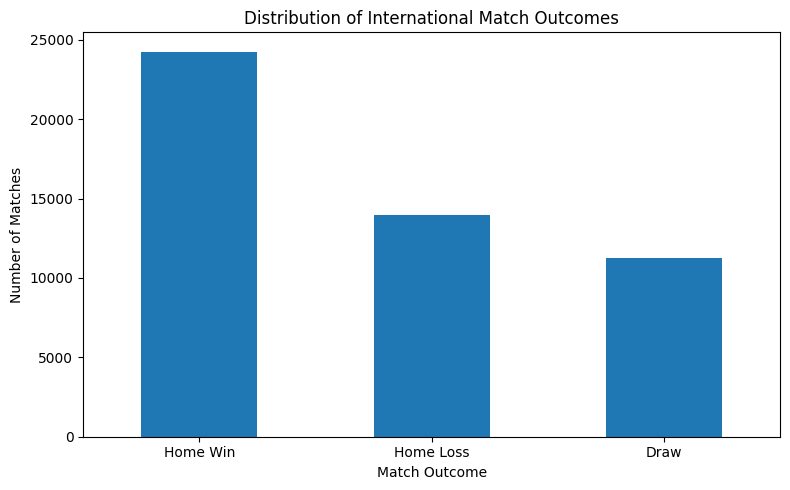

In [18]:
# ============================================================
# PHASE 4.3: ANALYSE OVERALL TARGET DISTRIBUTION
# ============================================================

# Examine the distribution of the prediction target

target_distribution = (
    completed_matches["result"]
    .value_counts()
    .to_frame("Number of Matches")
)

target_distribution["Percentage (%)"] = (
    completed_matches["result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("MATCH OUTCOME DISTRIBUTION")
print("-" * 40)

display(target_distribution)


# Visualise the target distribution
plt.figure(figsize=(8, 5))

completed_matches["result"].value_counts().plot(
    kind="bar"
)

plt.title(
    "Distribution of International Match Outcomes"
)

plt.xlabel("Match Outcome")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# PHASE 4.4: ANALYSE FIFA WORLD CUP TARGET DISTRIBUTION
# ============================================================

world_cup_completed = completed_matches[
    completed_matches["tournament"]
    == "FIFA World Cup"
].copy()

world_cup_distribution = (
    world_cup_completed["result"]
    .value_counts()
    .to_frame("Number of Matches")
)

world_cup_distribution["Percentage (%)"] = (
    world_cup_completed["result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("FIFA WORLD CUP OUTCOME DISTRIBUTION")
print("-" * 50)

print(
    f"Completed FIFA World Cup matches: "
    f"{len(world_cup_completed):,}"
)

display(world_cup_distribution)

FIFA WORLD CUP OUTCOME DISTRIBUTION
--------------------------------------------------
Completed FIFA World Cup matches: 1,054


,Number of Matches,Percentage (%)
result,,
Home Win,483,45.83
Home Loss,334,31.69
Draw,237,22.49


In [20]:
# ============================================================
# PHASE 4.5: PROTECT AGAINST TARGET LEAKAGE
# ============================================================

# Final scores are used only to construct the target variable.
# They must not be included as predictor variables because
# they directly reveal the match outcome.

leakage_columns = [
    "home_score",
    "away_score"
]

print("DATA LEAKAGE CONTROL")
print("-" * 40)

print("Columns used to construct the target:")

for column in leakage_columns:
    print(f"- {column}")

print(
    "\nThese columns will NOT be used as direct "
    "predictor variables."
)

DATA LEAKAGE CONTROL
----------------------------------------
Columns used to construct the target:
- home_score
- away_score

These columns will NOT be used as direct predictor variables.


# **PHASE 5: HISTORICAL FEATURE ENGINEERING**

In [21]:
# ============================================================
# PHASE 5.1: BUILD COMPLETE CHRONOLOGICAL TIMELINE
# ============================================================

# Combine:
# 1. Completed historical matches
# 2. Unscored prediction fixtures

timeline = pd.concat(
    [
        completed_matches,
        prediction_fixtures
    ],
    ignore_index=True
)

# Sort all records chronologically
timeline = (
    timeline
    .sort_values("date")
    .reset_index(drop=True)
)

print("FEATURE ENGINEERING TIMELINE")
print("-" * 50)

print(
    f"Total records              : "
    f"{len(timeline):,}"
)

print(
    f"Completed matches          : "
    f"{timeline['home_score'].notna().sum():,}"
)

print(
    f"Unscored fixtures          : "
    f"{timeline['home_score'].isna().sum():,}"
)

print(
    f"Date range                 : "
    f"{timeline['date'].min().date()} "
    f"to {timeline['date'].max().date()}"
)

FEATURE ENGINEERING TIMELINE
--------------------------------------------------
Total records              : 49,502
Completed matches          : 49,495
Unscored fixtures          : 7
Date range                 : 1872-11-30 to 2026-07-09


In [22]:
# ============================================================
# PHASE 5.2: DEFINE TEAM PERFORMANCE FEATURE FUNCTION
# ============================================================

from collections import defaultdict, deque


def calculate_team_features(history, window_size=5):
    """
    Calculate a team's pre-match performance features using
    only its most recent historical matches.

    Parameters
    ----------
    history : list or deque
        Previous match records of a team.

    window_size : int
        Number of recent matches used to represent current form.

    Returns
    -------
    dict
        Numerical pre-match performance features.
    """

    # Select only the most recent matches
    recent_matches = list(history)[-window_size:]

    matches_available = len(recent_matches)

    # Cold-start case: no previous history is available
    if matches_available == 0:
        return {
            "recent_win_rate": np.nan,
            "recent_draw_rate": np.nan,
            "avg_goals_scored": np.nan,
            "avg_goals_conceded": np.nan,
            "recent_goal_difference": np.nan,
            "matches_available": 0
        }

    # Count recent wins
    wins = sum(
        match["result"] == "Win"
        for match in recent_matches
    )

    # Count recent draws
    draws = sum(
        match["result"] == "Draw"
        for match in recent_matches
    )

    # Extract goals scored
    goals_scored = [
        match["goals_scored"]
        for match in recent_matches
    ]

    # Extract goals conceded
    goals_conceded = [
        match["goals_conceded"]
        for match in recent_matches
    ]

    return {
        "recent_win_rate":
            wins / matches_available,

        "recent_draw_rate":
            draws / matches_available,

        "avg_goals_scored":
            np.mean(goals_scored),

        "avg_goals_conceded":
            np.mean(goals_conceded),

        "recent_goal_difference":
            np.mean(goals_scored)
            - np.mean(goals_conceded),

        "matches_available":
            matches_available
    }

In [23]:
# ============================================================
# PHASE 5.3: DEFINE LEAKAGE-FREE HISTORICAL FEATURE GENERATOR
# ============================================================

def generate_historical_features(
    match_data,
    window_size=5
):
    """
    Generate leakage-free pre-match historical features.

    Features for all matches on the same date are calculated
    before any results from that date are added to team history.

    This prevents current-match, future-match, and same-day
    result leakage.
    """

    # Sort all records chronologically
    data = (
        match_data
        .sort_values("date")
        .reset_index(drop=True)
        .copy()
    )

    # Store recent match histories for each team
    team_history = defaultdict(
        lambda: deque(maxlen=window_size)
    )

    # Store generated feature rows
    feature_rows = []

    # Process matches one calendar date at a time
    for current_date, daily_matches in data.groupby(
        "date",
        sort=True
    ):

        # Temporarily store completed matches from this date
        daily_updates = []

        # ----------------------------------------------------
        # STEP 1:
        # Calculate features before adding today's results
        # ----------------------------------------------------

        for index, row in daily_matches.iterrows():

            home_team = row["home_team"]
            away_team = row["away_team"]

            # Calculate home-team pre-match features
            home_features = calculate_team_features(
                team_history[home_team],
                window_size
            )

            # Calculate away-team pre-match features
            away_features = calculate_team_features(
                team_history[away_team],
                window_size
            )

            # Store generated features
            feature_rows.append({
                "index": index,

                "home_recent_win_rate":
                    home_features["recent_win_rate"],

                "away_recent_win_rate":
                    away_features["recent_win_rate"],

                "home_recent_draw_rate":
                    home_features["recent_draw_rate"],

                "away_recent_draw_rate":
                    away_features["recent_draw_rate"],

                "home_avg_goals_scored":
                    home_features["avg_goals_scored"],

                "away_avg_goals_scored":
                    away_features["avg_goals_scored"],

                "home_avg_goals_conceded":
                    home_features["avg_goals_conceded"],

                "away_avg_goals_conceded":
                    away_features["avg_goals_conceded"],

                "home_recent_goal_difference":
                    home_features["recent_goal_difference"],

                "away_recent_goal_difference":
                    away_features["recent_goal_difference"],

                "home_matches_available":
                    home_features["matches_available"],

                "away_matches_available":
                    away_features["matches_available"]
            })

            # Store completed matches for later history update
            if (
                pd.notna(row["home_score"])
                and pd.notna(row["away_score"])
            ):
                daily_updates.append(row)

        # ----------------------------------------------------
        # STEP 2:
        # Add today's completed results only after all
        # features for the current date have been calculated
        # ----------------------------------------------------

        for row in daily_updates:

            home_team = row["home_team"]
            away_team = row["away_team"]

            home_score = row["home_score"]
            away_score = row["away_score"]

            # Determine result from each team's perspective
            if home_score > away_score:
                home_result = "Win"
                away_result = "Loss"

            elif home_score < away_score:
                home_result = "Loss"
                away_result = "Win"

            else:
                home_result = "Draw"
                away_result = "Draw"

            # Update home-team history
            team_history[home_team].append({
                "result": home_result,
                "goals_scored": home_score,
                "goals_conceded": away_score
            })

            # Update away-team history
            team_history[away_team].append({
                "result": away_result,
                "goals_scored": away_score,
                "goals_conceded": home_score
            })

    # Convert generated features into a DataFrame
    feature_df = pd.DataFrame(feature_rows)

    feature_df = (
        feature_df
        .set_index("index")
        .sort_index()
    )

    # Combine original match data with generated features
    result_df = pd.concat(
        [
            data,
            feature_df
        ],
        axis=1
    )

    return result_df

In [24]:
# ============================================================
# PHASE 5.4: GENERATE HISTORICAL FEATURES
# ============================================================

# Use the five most recent matches to represent team form
RECENT_MATCH_WINDOW = 5

featured_data = generate_historical_features(
    timeline,
    window_size=RECENT_MATCH_WINDOW
)

print("HISTORICAL FEATURE ENGINEERING COMPLETED")
print("-" * 60)

print(
    f"Number of processed records: "
    f"{len(featured_data):,}"
)

print(
    f"Recent match window: "
    f"{RECENT_MATCH_WINDOW}"
)

print(
    f"Number of columns after feature engineering: "
    f"{featured_data.shape[1]}"
)

HISTORICAL FEATURE ENGINEERING COMPLETED
------------------------------------------------------------
Number of processed records: 49,502
Recent match window: 5
Number of columns after feature engineering: 22


In [25]:
# ============================================================
# PHASE 5.5: PREVIEW ENGINEERED FEATURES
# ============================================================

engineered_feature_columns = [
    "date",
    "home_team",
    "away_team",
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_draw_rate",
    "away_recent_draw_rate",
    "home_avg_goals_scored",
    "away_avg_goals_scored",
    "home_avg_goals_conceded",
    "away_avg_goals_conceded",
    "home_recent_goal_difference",
    "away_recent_goal_difference",
    "home_matches_available",
    "away_matches_available"
]

print("ENGINEERED FEATURE SAMPLE")
print("-" * 50)

display(
    featured_data[
        engineered_feature_columns
    ].tail(10)
)

ENGINEERED FEATURE SAMPLE
--------------------------------------------------


,date,home_team,away_team,home_recent_win_rate,away_recent_win_rate,home_recent_draw_rate,away_recent_draw_rate,home_avg_goals_scored,away_avg_goals_scored,home_avg_goals_conceded,away_avg_goals_conceded,home_recent_goal_difference,away_recent_goal_difference,home_matches_available,away_matches_available
49492,2026-07-03,Colombia,Ghana,0.8,0.2,0.2,0.4,1.8,0.6,0.4,1.0,1.4,-0.4,5,5
49493,2026-07-04,Canada,Morocco,0.4,0.4,0.4,0.6,2.0,1.6,0.8,1.0,1.2,0.6,5,5
49494,2026-07-04,Paraguay,France,0.4,1.0,0.4,0.0,1.4,3.2,1.0,0.6,0.4,2.6,5,5
49495,2026-07-05,Mexico,England,1.0,0.8,0.0,0.2,2.6,2.2,0.2,0.6,2.4,1.6,5,5
49496,2026-07-05,Brazil,Norway,0.8,0.6,0.2,0.2,2.2,2.2,0.6,1.8,1.6,0.4,5,5
49497,2026-07-06,Argentina,Egypt,1.0,0.2,0.0,0.6,2.8,1.4,0.6,1.2,2.2,0.2,5,5
49498,2026-07-06,Switzerland,Colombia,0.6,0.8,0.4,0.2,2.0,1.4,0.8,0.2,1.2,1.2,5,5
49499,2026-07-06,Portugal,Spain,0.6,0.8,0.4,0.2,2.0,2.2,0.6,0.2,1.4,2.0,5,5
49500,2026-07-06,United States,Belgium,0.6,0.6,0.0,0.4,2.2,2.8,1.2,0.8,1.0,2.0,5,5
49501,2026-07-09,France,Morocco,1.0,0.6,0.0,0.4,2.8,2.0,0.4,0.8,2.4,1.2,5,5


In [26]:
# ============================================================
# PHASE 5.6: VALIDATE TEMPORAL LEAKAGE PREVENTION
# ============================================================

# Inspect the first chronological match in the dataset
first_match = featured_data.iloc[0]

print("TEMPORAL LEAKAGE VALIDATION")
print("-" * 50)

print(
    f"Date      : "
    f"{first_match['date'].date()}"
)

print(
    f"Home team : "
    f"{first_match['home_team']}"
)

print(
    f"Away team : "
    f"{first_match['away_team']}"
)

print(
    f"\nHome historical matches available: "
    f"{first_match['home_matches_available']}"
)

print(
    f"Away historical matches available: "
    f"{first_match['away_matches_available']}"
)

print(
    "\nExpected result: Both values should be 0 because "
    "no earlier matches exist in the dataset."
)

TEMPORAL LEAKAGE VALIDATION
--------------------------------------------------
Date      : 1872-11-30
Home team : Scotland
Away team : England

Home historical matches available: 0
Away historical matches available: 0

Expected result: Both values should be 0 because no earlier matches exist in the dataset.


In [27]:
# ============================================================
# PHASE 5.7: INSPECT MODERN WORLD CUP FEATURE EXAMPLE
# ============================================================

# Select the most recent completed FIFA World Cup match

modern_world_cup_match = featured_data[
    (
        featured_data["tournament"]
        == "FIFA World Cup"
    )
    &
    featured_data["home_score"].notna()
].tail(1)

print("MODERN FIFA WORLD CUP FEATURE EXAMPLE")
print("-" * 55)

display(
    modern_world_cup_match[
        [
            "date",
            "home_team",
            "away_team",
            "home_recent_win_rate",
            "away_recent_win_rate",
            "home_avg_goals_scored",
            "away_avg_goals_scored",
            "home_recent_goal_difference",
            "away_recent_goal_difference",
            "result"
        ]
    ]
)

MODERN FIFA WORLD CUP FEATURE EXAMPLE
-------------------------------------------------------


,date,home_team,away_team,home_recent_win_rate,away_recent_win_rate,home_avg_goals_scored,away_avg_goals_scored,home_recent_goal_difference,away_recent_goal_difference,result
49494,2026-07-04,Paraguay,France,0.4,1.0,1.4,3.2,0.4,2.6,Home Loss


In [28]:
# ============================================================
# PHASE 5.8: SEPARATE MODEL AND PREDICTION DATA
# ============================================================

# Completed matches are used for model development
model_data = featured_data[
    featured_data["home_score"].notna()
    &
    featured_data["away_score"].notna()
].copy()

# Unscored fixtures are preserved for final prediction
final_prediction_data = featured_data[
    featured_data["home_score"].isna()
    |
    featured_data["away_score"].isna()
].copy()

print("POST-FEATURE-ENGINEERING DATASETS")
print("-" * 55)

print(
    f"Model development records : "
    f"{len(model_data):,}"
)

print(
    f"Final prediction fixtures : "
    f"{len(final_prediction_data):,}"
)

POST-FEATURE-ENGINEERING DATASETS
-------------------------------------------------------
Model development records : 49,495
Final prediction fixtures : 7


In [29]:
# ============================================================
# PHASE 5.9: AUDIT COLD-START MISSING VALUES
# ============================================================

historical_features = [
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_draw_rate",
    "away_recent_draw_rate",
    "home_avg_goals_scored",
    "away_avg_goals_scored",
    "home_avg_goals_conceded",
    "away_avg_goals_conceded",
    "home_recent_goal_difference",
    "away_recent_goal_difference",
    "home_matches_available",
    "away_matches_available"
]

feature_missing_summary = pd.DataFrame({
    "Missing Count":
        model_data[historical_features]
        .isnull()
        .sum(),

    "Missing Percentage (%)":
        (
            model_data[historical_features]
            .isnull()
            .mean()
            * 100
        ).round(3)
})

print("ENGINEERED FEATURE MISSING VALUES")
print("-" * 55)

display(feature_missing_summary)

ENGINEERED FEATURE MISSING VALUES
-------------------------------------------------------


,Missing Count,Missing Percentage (%)
home_recent_win_rate,141,0.285
away_recent_win_rate,195,0.394
home_recent_draw_rate,141,0.285
away_recent_draw_rate,195,0.394
home_avg_goals_scored,141,0.285
away_avg_goals_scored,195,0.394
home_avg_goals_conceded,141,0.285
away_avg_goals_conceded,195,0.394
home_recent_goal_difference,141,0.285
away_recent_goal_difference,195,0.394


# **PHASE 6: FINAL MODELLING DATASET PREPARATION**

In [30]:
# ============================================================
# PHASE 6.1: CALCULATE COLD-START FALLBACK VALUES
# ============================================================

# Total number of team appearances
total_team_appearances = len(model_data) * 2

# Overall probability that a team wins a match
overall_win_rate = (
    (model_data["result"] != "Draw").sum()
    / total_team_appearances
)

# Overall probability that a team draws a match
overall_draw_rate = (
    (model_data["result"] == "Draw").sum()
    * 2
    / total_team_appearances
)

# Overall average goals scored by one team per match
overall_avg_goals = (
    model_data["home_score"].sum()
    + model_data["away_score"].sum()
) / total_team_appearances

# Define neutral fallback values
cold_start_fill_values = {
    "home_recent_win_rate":
        overall_win_rate,

    "away_recent_win_rate":
        overall_win_rate,

    "home_recent_draw_rate":
        overall_draw_rate,

    "away_recent_draw_rate":
        overall_draw_rate,

    "home_avg_goals_scored":
        overall_avg_goals,

    "away_avg_goals_scored":
        overall_avg_goals,

    "home_avg_goals_conceded":
        overall_avg_goals,

    "away_avg_goals_conceded":
        overall_avg_goals,

    "home_recent_goal_difference":
        0.0,

    "away_recent_goal_difference":
        0.0
}

print("COLD-START FALLBACK VALUES")
print("-" * 55)

for feature, value in cold_start_fill_values.items():
    print(
        f"{feature:<35}: "
        f"{value:.4f}"
    )

COLD-START FALLBACK VALUES
-------------------------------------------------------
home_recent_win_rate               : 0.3863
away_recent_win_rate               : 0.3863
home_recent_draw_rate              : 0.2274
away_recent_draw_rate              : 0.2274
home_avg_goals_scored              : 1.4696
away_avg_goals_scored              : 1.4696
home_avg_goals_conceded            : 1.4696
away_avg_goals_conceded            : 1.4696
home_recent_goal_difference        : 0.0000
away_recent_goal_difference        : 0.0000


In [31]:
# ============================================================
# PHASE 6.2: APPLY COLD-START TREATMENT
# ============================================================

# Count missing engineered values before treatment
missing_before_cold_start = (
    model_data[historical_features]
    .isnull()
    .sum()
    .sum()
)

# Apply identical fallback logic to modelling data
model_data = model_data.fillna(
    value=cold_start_fill_values
)

# Apply identical fallback logic to prediction fixtures
final_prediction_data = final_prediction_data.fillna(
    value=cold_start_fill_values
)

# Count missing engineered values after treatment
missing_after_cold_start = (
    model_data[historical_features]
    .isnull()
    .sum()
    .sum()
)

print("COLD-START TREATMENT")
print("-" * 55)

print(
    f"Missing engineered values before treatment: "
    f"{missing_before_cold_start}"
)

print(
    f"Missing engineered values after treatment : "
    f"{missing_after_cold_start}"
)

COLD-START TREATMENT
-------------------------------------------------------
Missing engineered values before treatment: 1680
Missing engineered values after treatment : 0


In [32]:
# ============================================================
# PHASE 6.3: CREATE TEAM STRENGTH DIFFERENCE FEATURES
# ============================================================

def add_difference_features(data):
    """
    Create relative team-strength indicators by subtracting
    the away team's recent performance from the home team's
    recent performance.
    """

    data = data.copy()

    data["win_rate_difference"] = (
        data["home_recent_win_rate"]
        - data["away_recent_win_rate"]
    )

    data["draw_rate_difference"] = (
        data["home_recent_draw_rate"]
        - data["away_recent_draw_rate"]
    )

    data["goals_scored_difference"] = (
        data["home_avg_goals_scored"]
        - data["away_avg_goals_scored"]
    )

    data["goals_conceded_difference"] = (
        data["home_avg_goals_conceded"]
        - data["away_avg_goals_conceded"]
    )

    data["goal_difference_difference"] = (
        data["home_recent_goal_difference"]
        - data["away_recent_goal_difference"]
    )

    data["experience_difference"] = (
        data["home_matches_available"]
        - data["away_matches_available"]
    )

    return data


# Apply difference feature construction
model_data = add_difference_features(
    model_data
)

final_prediction_data = add_difference_features(
    final_prediction_data
)

# Store difference feature names
difference_features = [
    "win_rate_difference",
    "draw_rate_difference",
    "goals_scored_difference",
    "goals_conceded_difference",
    "goal_difference_difference",
    "experience_difference"
]

print("STRENGTH-DIFFERENCE FEATURES CREATED")
print("-" * 55)

display(
    model_data[
        [
            "home_team",
            "away_team"
        ]
        + difference_features
    ].tail()
)

STRENGTH-DIFFERENCE FEATURES CREATED
-------------------------------------------------------


,home_team,away_team,win_rate_difference,draw_rate_difference,goals_scored_difference,goals_conceded_difference,goal_difference_difference,experience_difference
49490,Australia,Egypt,-0.2,0.0,-0.8,-0.2,-0.6,0
49491,Argentina,Cape Verde,0.8,-0.6,1.6,-0.8,2.4,0
49492,Colombia,Ghana,0.6,-0.2,1.2,-0.6,1.8,0
49493,Canada,Morocco,0.0,-0.2,0.4,-0.2,0.6,0
49494,Paraguay,France,-0.6,0.4,-1.8,0.4,-2.2,0


In [33]:
# ============================================================
# PHASE 6.4: CREATE TOURNAMENT CATEGORIES
# ============================================================

def categorize_tournament(tournament):
    """
    Group the original tournament names into four broader
    competition categories.
    """

    if tournament == "FIFA World Cup":
        return "World Cup"

    elif tournament == "FIFA World Cup qualification":
        return "World Cup Qualification"

    elif tournament == "Friendly":
        return "Friendly"

    else:
        return "Other Competitive"


# Categorise modelling data
model_data["tournament_category"] = (
    model_data["tournament"]
    .apply(categorize_tournament)
)

# Categorise final prediction fixtures
final_prediction_data["tournament_category"] = (
    final_prediction_data["tournament"]
    .apply(categorize_tournament)
)

print("TOURNAMENT CATEGORY DISTRIBUTION")
print("-" * 55)

display(
    model_data["tournament_category"]
    .value_counts()
    .to_frame("Number of Matches")
)

TOURNAMENT CATEGORY DISTRIBUTION
-------------------------------------------------------


,Number of Matches
tournament_category,
Other Competitive,21282
Friendly,18388
World Cup Qualification,8771
World Cup,1054


In [34]:
# ============================================================
# PHASE 6.5: ONE-HOT ENCODE TOURNAMENT CATEGORIES
# ============================================================

# One-hot encode modelling data
model_data = pd.get_dummies(
    model_data,
    columns=["tournament_category"],
    prefix="tournament",
    dtype=int
)

# One-hot encode final prediction data
final_prediction_data = pd.get_dummies(
    final_prediction_data,
    columns=["tournament_category"],
    prefix="tournament",
    dtype=int
)

# Identify tournament dummy variables
tournament_dummy_columns = [
    column
    for column in model_data.columns
    if column.startswith("tournament_")
    and column != "tournament"
]

# Ensure prediction data contains all modelling columns
for column in tournament_dummy_columns:
    if column not in final_prediction_data.columns:
        final_prediction_data[column] = 0

print("TOURNAMENT ENCODING COMPLETED")
print("-" * 55)

print("Encoded tournament columns:")

for column in tournament_dummy_columns:
    print(f"- {column}")

TOURNAMENT ENCODING COMPLETED
-------------------------------------------------------
Encoded tournament columns:
- tournament_Friendly
- tournament_Other Competitive
- tournament_World Cup
- tournament_World Cup Qualification


In [35]:
# ============================================================
# PHASE 6.6: ENCODE NEUTRAL VENUE
# ============================================================

# Convert Boolean values into binary numerical values
model_data["neutral"] = (
    model_data["neutral"]
    .astype(int)
)

final_prediction_data["neutral"] = (
    final_prediction_data["neutral"]
    .astype(int)
)

print("NEUTRAL VENUE ENCODING")
print("-" * 55)

print(
    model_data["neutral"]
    .value_counts()
    .sort_index()
)

print("\nEncoding:")
print("0 = Non-neutral venue")
print("1 = Neutral venue")

NEUTRAL VENUE ENCODING
-------------------------------------------------------
neutral
0    36358
1    13137
Name: count, dtype: int64

Encoding:
0 = Non-neutral venue
1 = Neutral venue


In [36]:
# ============================================================
# PHASE 6.7: DEFINE FINAL PREDICTOR VARIABLES
# ============================================================

# Original historical team-performance features
base_features = [
    "home_recent_win_rate",
    "away_recent_win_rate",
    "home_recent_draw_rate",
    "away_recent_draw_rate",
    "home_avg_goals_scored",
    "away_avg_goals_scored",
    "home_avg_goals_conceded",
    "away_avg_goals_conceded",
    "home_recent_goal_difference",
    "away_recent_goal_difference",
    "home_matches_available",
    "away_matches_available"
]

# Contextual match features
context_features = [
    "neutral"
] + tournament_dummy_columns

# Complete predictor set
feature_columns = (
    base_features
    + difference_features
    + context_features
)

print("FINAL MODEL FEATURES")
print("-" * 55)

print(
    f"Number of predictor variables: "
    f"{len(feature_columns)}"
)

for number, feature in enumerate(
    feature_columns,
    start=1
):
    print(
        f"{number:>2}. "
        f"{feature}"
    )

FINAL MODEL FEATURES
-------------------------------------------------------
Number of predictor variables: 23
 1. home_recent_win_rate
 2. away_recent_win_rate
 3. home_recent_draw_rate
 4. away_recent_draw_rate
 5. home_avg_goals_scored
 6. away_avg_goals_scored
 7. home_avg_goals_conceded
 8. away_avg_goals_conceded
 9. home_recent_goal_difference
10. away_recent_goal_difference
11. home_matches_available
12. away_matches_available
13. win_rate_difference
14. draw_rate_difference
15. goals_scored_difference
16. goals_conceded_difference
17. goal_difference_difference
18. experience_difference
19. neutral
20. tournament_Friendly
21. tournament_Other Competitive
22. tournament_World Cup
23. tournament_World Cup Qualification


In [37]:
# ============================================================
# PHASE 6.8: BUILD FINAL FEATURE MATRIX AND TARGET VECTOR
# ============================================================

# Predictor matrix
X = model_data[feature_columns].copy()

# Target vector
y = model_data["result"].copy()

# Check for infinite numerical values
infinite_value_count = (
    np.isinf(
        X.select_dtypes(include=np.number)
    )
    .sum()
    .sum()
)

print("FINAL MODELLING DATASET")
print("-" * 55)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

print(
    f"Missing predictor values: "
    f"{X.isnull().sum().sum()}"
)

print(
    f"Infinite predictor values: "
    f"{infinite_value_count}"
)

print("\nTarget classes:")

for target_class in sorted(y.unique()):
    print(f"- {target_class}")

FINAL MODELLING DATASET
-------------------------------------------------------
X shape: (49495, 23)
y shape: (49495,)
Missing predictor values: 0
Infinite predictor values: 0

Target classes:
- Draw
- Home Loss
- Home Win


# **Phase 7 : Strict Chronological Train-Test Split**

In [38]:
# ============================================================
# PHASE 7.1: PERFORM STRICT CHRONOLOGICAL TRAIN-TEST SPLIT
# ============================================================

# Identify the approximate 80% chronological boundary
approximate_split_index = int(len(model_data) * 0.80)

# Obtain the date at the approximate split position
split_date = model_data.iloc[
    approximate_split_index
]["date"]

# Keep all matches before the split date in training
train_mask = model_data["date"] < split_date

# Keep all matches on or after the split date in testing
test_mask = model_data["date"] >= split_date


X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

train_metadata = model_data.loc[train_mask].copy()
test_metadata = model_data.loc[test_mask].copy()


print("STRICT CHRONOLOGICAL TRAIN-TEST SPLIT")
print("-" * 60)

print(f"Split boundary date: {split_date.date()}")

print(
    f"\nTraining records : {len(X_train):,} "
    f"({len(X_train) / len(X) * 100:.2f}%)"
)

print(
    f"Testing records  : {len(X_test):,} "
    f"({len(X_test) / len(X) * 100:.2f}%)"
)

print(
    f"\nTraining period : "
    f"{train_metadata['date'].min().date()} "
    f"to {train_metadata['date'].max().date()}"
)

print(
    f"Testing period  : "
    f"{test_metadata['date'].min().date()} "
    f"to {test_metadata['date'].max().date()}"
)

STRICT CHRONOLOGICAL TRAIN-TEST SPLIT
------------------------------------------------------------
Split boundary date: 2016-03-29

Training records : 39,587 (79.98%)
Testing records  : 9,908 (20.02%)

Training period : 1872-11-30 to 2016-03-28
Testing period  : 2016-03-29 to 2026-07-04


In [39]:
# ============================================================
# PHASE 7.2: VALIDATE STRICT TEMPORAL SEPARATION
# ============================================================

latest_training_date = train_metadata["date"].max()
earliest_testing_date = test_metadata["date"].min()

print("STRICT TEMPORAL SPLIT VALIDATION")
print("-" * 60)

print(
    f"Latest training date : "
    f"{latest_training_date.date()}"
)

print(
    f"Earliest testing date: "
    f"{earliest_testing_date.date()}"
)

if latest_training_date < earliest_testing_date:
    print(
        "\nPASS: Strict temporal separation confirmed."
    )

    print(
        "No calendar date appears in both the "
        "training and testing datasets."
    )

else:
    print(
        "\nFAIL: Temporal overlap detected."
    )

STRICT TEMPORAL SPLIT VALIDATION
------------------------------------------------------------
Latest training date : 2016-03-28
Earliest testing date: 2016-03-29

PASS: Strict temporal separation confirmed.
No calendar date appears in both the training and testing datasets.


In [40]:
# ============================================================
# PHASE 7.3: COMPARE CLASS DISTRIBUTION
# ============================================================

class_distribution = pd.DataFrame({
    "Training (%)":
        y_train.value_counts(normalize=True)
        .mul(100)
        .round(2),

    "Testing (%)":
        y_test.value_counts(normalize=True)
        .mul(100)
        .round(2)
})

print("TRAINING AND TESTING CLASS DISTRIBUTION")
print("-" * 60)

display(class_distribution)

TRAINING AND TESTING CLASS DISTRIBUTION
------------------------------------------------------------


,Training (%),Testing (%)
result,,
Home Win,49.34,47.67
Home Loss,28.06,29.02
Draw,22.60,23.31


In [41]:
# ============================================================
# PHASE 7.4: CREATE FIFA WORLD CUP TEST SUBSET
# ============================================================

world_cup_test_mask = (
    test_metadata["tournament"] ==
    "FIFA World Cup"
)

X_test_world_cup = X_test.loc[
    world_cup_test_mask
].copy()

y_test_world_cup = y_test.loc[
    world_cup_test_mask
].copy()

world_cup_test_metadata = test_metadata.loc[
    world_cup_test_mask
].copy()

print("FIFA WORLD CUP TEST SUBSET")
print("-" * 60)

print(
    f"World Cup matches in test set: "
    f"{len(X_test_world_cup):,}"
)

if len(X_test_world_cup) > 0:
    print(
        f"Date range: "
        f"{world_cup_test_metadata['date'].min().date()} "
        f"to "
        f"{world_cup_test_metadata['date'].max().date()}"
    )

FIFA WORLD CUP TEST SUBSET
------------------------------------------------------------
World Cup matches in test set: 218
Date range: 2018-06-14 to 2026-07-04


# **PHASE 8 : LOGISTIC REGRESSION**

In [42]:
# ============================================================
# PHASE 8.1: STANDARDISE PREDICTOR VARIABLES
# ============================================================

# Create the feature scaler
scaler = StandardScaler()

# Learn scaling parameters from training data only
X_train_scaled = scaler.fit_transform(
    X_train
)

# Apply the same transformation to testing data
X_test_scaled = scaler.transform(
    X_test
)

# Apply the same transformation to the World Cup test subset
X_test_world_cup_scaled = scaler.transform(
    X_test_world_cup
)

print("FEATURE STANDARDISATION COMPLETED")
print("-" * 60)

print(
    f"Training data shape        : "
    f"{X_train_scaled.shape}"
)

print(
    f"Testing data shape         : "
    f"{X_test_scaled.shape}"
)

print(
    f"World Cup test data shape  : "
    f"{X_test_world_cup_scaled.shape}"
)

print(
    "\nThe scaler was fitted using training data only."
)

print(
    "Testing data was transformed using the same "
    "training-derived parameters."
)

FEATURE STANDARDISATION COMPLETED
------------------------------------------------------------
Training data shape        : (39587, 23)
Testing data shape         : (9908, 23)
World Cup test data shape  : (218, 23)

The scaler was fitted using training data only.
Testing data was transformed using the same training-derived parameters.


In [43]:
# ============================================================
# PHASE 8.2: TRAIN LOGISTIC REGRESSION MODEL
# ============================================================

# Create the Logistic Regression classifier
logistic_regression_model = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

# Train the model using standardised training data
logistic_regression_model.fit(
    X_train_scaled,
    y_train
)

print("LOGISTIC REGRESSION TRAINING COMPLETED")
print("-" * 60)

print(
    f"Training records : "
    f"{len(X_train):,}"
)

print(
    f"Predictor variables: "
    f"{X_train.shape[1]}"
)

print(
    f"Number of classes : "
    f"{len(logistic_regression_model.classes_)}"
)

print("\nModel classes:")

for model_class in logistic_regression_model.classes_:
    print(f"- {model_class}")

LOGISTIC REGRESSION TRAINING COMPLETED
------------------------------------------------------------
Training records : 39,587
Predictor variables: 23
Number of classes : 3

Model classes:
- Draw
- Home Loss
- Home Win


In [44]:
# ============================================================
# PHASE 8.3: GENERATE OVERALL TEST PREDICTIONS
# ============================================================

# Predict match outcome classes
lr_test_predictions = (
    logistic_regression_model.predict(
        X_test_scaled
    )
)

# Predict class probabilities
lr_test_probabilities = (
    logistic_regression_model.predict_proba(
        X_test_scaled
    )
)

print("LOGISTIC REGRESSION PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of test predictions: "
    f"{len(lr_test_predictions):,}"
)

print(
    f"Probability matrix shape  : "
    f"{lr_test_probabilities.shape}"
)

print("\nFirst 10 predicted outcomes:")

print(
    lr_test_predictions[:10]
)

LOGISTIC REGRESSION PREDICTIONS GENERATED
------------------------------------------------------------
Number of test predictions: 9,908
Probability matrix shape  : (9908, 3)

First 10 predicted outcomes:
['Home Win' 'Home Loss' 'Home Win' 'Home Win' 'Home Win' 'Home Win'
 'Home Win' 'Home Win' 'Home Win' 'Home Loss']


In [45]:
# ============================================================
# PHASE 8.4: EVALUATE OVERALL TEST PERFORMANCE
# ============================================================

# Calculate overall evaluation metrics
lr_accuracy = accuracy_score(
    y_test,
    lr_test_predictions
)

lr_precision = precision_score(
    y_test,
    lr_test_predictions,
    average="macro",
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_test_predictions,
    average="macro",
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_test_predictions,
    average="macro",
    zero_division=0
)

print("LOGISTIC REGRESSION — OVERALL TEST PERFORMANCE")
print("-" * 65)

print(
    f"Accuracy        : "
    f"{lr_accuracy:.4f}"
)

print(
    f"Macro Precision : "
    f"{lr_precision:.4f}"
)

print(
    f"Macro Recall    : "
    f"{lr_recall:.4f}"
)

print(
    f"Macro F1-Score  : "
    f"{lr_f1:.4f}"
)

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test,
        lr_test_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION — OVERALL TEST PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.5288
Macro Precision : 0.4809
Macro Recall    : 0.4179
Macro F1-Score  : 0.3650

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.40      0.00      0.00      2310
   Home Loss       0.51      0.37      0.43      2875
    Home Win       0.53      0.88      0.67      4723

    accuracy                           0.53      9908
   macro avg       0.48      0.42      0.36      9908
weighted avg       0.50      0.53      0.44      9908



In [46]:
# ============================================================
# PHASE 8.5: GENERATE FIFA WORLD CUP TEST PREDICTIONS
# ============================================================

# Generate predictions for World Cup matches
lr_world_cup_predictions = (
    logistic_regression_model.predict(
        X_test_world_cup_scaled
    )
)

# Generate prediction probabilities
lr_world_cup_probabilities = (
    logistic_regression_model.predict_proba(
        X_test_world_cup_scaled
    )
)

print("FIFA WORLD CUP PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of World Cup predictions: "
    f"{len(lr_world_cup_predictions):,}"
)

print("\nFirst 10 predicted outcomes:")

print(
    lr_world_cup_predictions[:10]
)

FIFA WORLD CUP PREDICTIONS GENERATED
------------------------------------------------------------
Number of World Cup predictions: 218

First 10 predicted outcomes:
['Home Win' 'Home Loss' 'Home Win' 'Home Loss' 'Home Win' 'Home Win'
 'Home Win' 'Home Win' 'Home Loss' 'Home Loss']


In [47]:
# ============================================================
# PHASE 8.6: EVALUATE FIFA WORLD CUP PERFORMANCE
# ============================================================

# Calculate World Cup-specific evaluation metrics
lr_wc_accuracy = accuracy_score(
    y_test_world_cup,
    lr_world_cup_predictions
)

lr_wc_precision = precision_score(
    y_test_world_cup,
    lr_world_cup_predictions,
    average="macro",
    zero_division=0
)

lr_wc_recall = recall_score(
    y_test_world_cup,
    lr_world_cup_predictions,
    average="macro",
    zero_division=0
)

lr_wc_f1 = f1_score(
    y_test_world_cup,
    lr_world_cup_predictions,
    average="macro",
    zero_division=0
)

print(
    "LOGISTIC REGRESSION — "
    "FIFA WORLD CUP PERFORMANCE"
)

print("-" * 65)

print(
    f"Accuracy        : "
    f"{lr_wc_accuracy:.4f}"
)

print(
    f"Macro Precision : "
    f"{lr_wc_precision:.4f}"
)

print(
    f"Macro Recall    : "
    f"{lr_wc_recall:.4f}"
)

print(
    f"Macro F1-Score  : "
    f"{lr_wc_f1:.4f}"
)

print("\nFIFA WORLD CUP CLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test_world_cup,
        lr_world_cup_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION — FIFA WORLD CUP PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.5138
Macro Precision : 0.3481
Macro Recall    : 0.4286
Macro F1-Score  : 0.3753

FIFA WORLD CUP CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.00      0.00      0.00        51
   Home Loss       0.54      0.47      0.50        70
    Home Win       0.50      0.81      0.62        97

    accuracy                           0.51       218
   macro avg       0.35      0.43      0.38       218
weighted avg       0.40      0.51      0.44       218



In [48]:
# ============================================================
# PHASE 8.7: STORE LOGISTIC REGRESSION RESULTS
# ============================================================

# Store overall test metrics
lr_overall_results = {
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Macro Precision": lr_precision,
    "Macro Recall": lr_recall,
    "Macro F1-Score": lr_f1
}

# Store FIFA World Cup-specific metrics
lr_world_cup_results = {
    "Model": "Logistic Regression",
    "Accuracy": lr_wc_accuracy,
    "Macro Precision": lr_wc_precision,
    "Macro Recall": lr_wc_recall,
    "Macro F1-Score": lr_wc_f1
}

print("LOGISTIC REGRESSION RESULTS STORED")
print("-" * 60)

print("\nOverall Test Results:")

display(
    pd.DataFrame(
        [lr_overall_results]
    )
)

print("\nFIFA World Cup Results:")

display(
    pd.DataFrame(
        [lr_world_cup_results]
    )
)

LOGISTIC REGRESSION RESULTS STORED
------------------------------------------------------------

Overall Test Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.528765,0.480949,0.417895,0.364987



FIFA World Cup Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.513761,0.348056,0.428621,0.375288


# **Phase 9 : Decision Tree**

In [49]:
# ============================================================
# PHASE 9.1: CONFIGURE AND TRAIN DECISION TREE MODEL
# ============================================================

decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=RANDOM_STATE
)

decision_tree_model.fit(
    X_train,
    y_train
)

print("DECISION TREE TRAINING COMPLETED")
print("-" * 60)

print(
    f"Training records   : "
    f"{len(X_train):,}"
)

print(
    f"Predictor variables: "
    f"{X_train.shape[1]}"
)

print(
    f"Maximum tree depth : "
    f"{decision_tree_model.get_depth()}"
)

print(
    f"Number of leaves   : "
    f"{decision_tree_model.get_n_leaves()}"
)

DECISION TREE TRAINING COMPLETED
------------------------------------------------------------
Training records   : 39,587
Predictor variables: 23
Maximum tree depth : 10
Number of leaves   : 498


In [50]:
# ============================================================
# PHASE 9.2: GENERATE OVERALL TEST PREDICTIONS
# ============================================================

dt_test_predictions = (
    decision_tree_model.predict(
        X_test
    )
)

dt_test_probabilities = (
    decision_tree_model.predict_proba(
        X_test
    )
)

print("DECISION TREE PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of test predictions: "
    f"{len(dt_test_predictions):,}"
)

print(
    f"Probability matrix shape  : "
    f"{dt_test_probabilities.shape}"
)

print("\nFirst 10 predicted outcomes:")

print(dt_test_predictions[:10])

DECISION TREE PREDICTIONS GENERATED
------------------------------------------------------------
Number of test predictions: 9,908
Probability matrix shape  : (9908, 3)

First 10 predicted outcomes:
['Home Win' 'Home Loss' 'Home Win' 'Home Win' 'Home Win' 'Home Win'
 'Home Win' 'Home Win' 'Home Win' 'Home Loss']


In [51]:
# ============================================================
# PHASE 9.3: EVALUATE OVERALL TEST PERFORMANCE
# ============================================================

dt_accuracy = accuracy_score(
    y_test,
    dt_test_predictions
)

dt_precision = precision_score(
    y_test,
    dt_test_predictions,
    average="macro",
    zero_division=0
)

dt_recall = recall_score(
    y_test,
    dt_test_predictions,
    average="macro",
    zero_division=0
)

dt_f1 = f1_score(
    y_test,
    dt_test_predictions,
    average="macro",
    zero_division=0
)

print("DECISION TREE — OVERALL TEST PERFORMANCE")
print("-" * 65)

print(f"Accuracy        : {dt_accuracy:.4f}")
print(f"Macro Precision : {dt_precision:.4f}")
print(f"Macro Recall    : {dt_recall:.4f}")
print(f"Macro F1-Score  : {dt_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test,
        dt_test_predictions,
        zero_division=0
    )
)

DECISION TREE — OVERALL TEST PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.5165
Macro Precision : 0.4415
Macro Recall    : 0.4183
Macro F1-Score  : 0.3915

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.29      0.06      0.11      2310
   Home Loss       0.50      0.35      0.42      2875
    Home Win       0.54      0.84      0.65      4723

    accuracy                           0.52      9908
   macro avg       0.44      0.42      0.39      9908
weighted avg       0.47      0.52      0.46      9908



In [52]:
# ============================================================
# PHASE 9.4: GENERATE FIFA WORLD CUP TEST PREDICTIONS
# ============================================================

dt_world_cup_predictions = (
    decision_tree_model.predict(
        X_test_world_cup
    )
)

dt_world_cup_probabilities = (
    decision_tree_model.predict_proba(
        X_test_world_cup
    )
)

print("FIFA WORLD CUP PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of World Cup predictions: "
    f"{len(dt_world_cup_predictions):,}"
)

print("\nFirst 10 predicted outcomes:")

print(dt_world_cup_predictions[:10])

FIFA WORLD CUP PREDICTIONS GENERATED
------------------------------------------------------------
Number of World Cup predictions: 218

First 10 predicted outcomes:
['Home Win' 'Draw' 'Home Win' 'Home Loss' 'Home Win' 'Home Win' 'Home Win'
 'Home Win' 'Home Loss' 'Home Loss']


In [53]:
# ============================================================
# PHASE 9.5: EVALUATE FIFA WORLD CUP PERFORMANCE
# ============================================================

dt_wc_accuracy = accuracy_score(
    y_test_world_cup,
    dt_world_cup_predictions
)

dt_wc_precision = precision_score(
    y_test_world_cup,
    dt_world_cup_predictions,
    average="macro",
    zero_division=0
)

dt_wc_recall = recall_score(
    y_test_world_cup,
    dt_world_cup_predictions,
    average="macro",
    zero_division=0
)

dt_wc_f1 = f1_score(
    y_test_world_cup,
    dt_world_cup_predictions,
    average="macro",
    zero_division=0
)

print(
    "DECISION TREE — FIFA WORLD CUP PERFORMANCE"
)

print("-" * 65)

print(f"Accuracy        : {dt_wc_accuracy:.4f}")
print(f"Macro Precision : {dt_wc_precision:.4f}")
print(f"Macro Recall    : {dt_wc_recall:.4f}")
print(f"Macro F1-Score  : {dt_wc_f1:.4f}")

print("\nFIFA WORLD CUP CLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test_world_cup,
        dt_world_cup_predictions,
        zero_division=0
    )
)

DECISION TREE — FIFA WORLD CUP PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.4725
Macro Precision : 0.4270
Macro Recall    : 0.4053
Macro F1-Score  : 0.3903

FIFA WORLD CUP CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.33      0.16      0.21        51
   Home Loss       0.44      0.29      0.35        70
    Home Win       0.50      0.77      0.61        97

    accuracy                           0.47       218
   macro avg       0.43      0.41      0.39       218
weighted avg       0.44      0.47      0.43       218



In [54]:
# ============================================================
# PHASE 9.6: STORE DECISION TREE RESULTS
# ============================================================

dt_overall_results = {
    "Model": "Decision Tree",
    "Accuracy": dt_accuracy,
    "Macro Precision": dt_precision,
    "Macro Recall": dt_recall,
    "Macro F1-Score": dt_f1
}

dt_world_cup_results = {
    "Model": "Decision Tree",
    "Accuracy": dt_wc_accuracy,
    "Macro Precision": dt_wc_precision,
    "Macro Recall": dt_wc_recall,
    "Macro F1-Score": dt_wc_f1
}

print("DECISION TREE RESULTS STORED")
print("-" * 60)

print("\nOverall Test Results:")

display(
    pd.DataFrame(
        [dt_overall_results]
    )
)

print("\nFIFA World Cup Results:")

display(
    pd.DataFrame(
        [dt_world_cup_results]
    )
)

DECISION TREE RESULTS STORED
------------------------------------------------------------

Overall Test Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Decision Tree,0.516451,0.441531,0.418307,0.391488



FIFA World Cup Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Decision Tree,0.472477,0.427044,0.405258,0.390305


In [55]:
# ============================================================
# PHASE 9.7: INSPECT DECISION TREE STRUCTURE
# ============================================================

tree_structure_summary = pd.DataFrame({
    "Property": [
        "Maximum Depth",
        "Number of Leaves",
        "Number of Predictor Variables",
        "Training Records"
    ],
    "Value": [
        decision_tree_model.get_depth(),
        decision_tree_model.get_n_leaves(),
        X_train.shape[1],
        len(X_train)
    ]
})

print("DECISION TREE STRUCTURE SUMMARY")
print("-" * 60)

display(tree_structure_summary)

DECISION TREE STRUCTURE SUMMARY
------------------------------------------------------------


,Property,Value
0,Maximum Depth,10
1,Number of Leaves,498
2,Number of Predictor Variables,23
3,Training Records,39587


# **PHASE 10 : RANDOM FOREST**

In [56]:
# ============================================================
# PHASE 10.1: CONFIGURE AND TRAIN RANDOM FOREST MODEL
# ============================================================

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

random_forest_model.fit(
    X_train,
    y_train
)

print("RANDOM FOREST TRAINING COMPLETED")
print("-" * 60)

print(
    f"Training records    : "
    f"{len(X_train):,}"
)

print(
    f"Predictor variables : "
    f"{X_train.shape[1]}"
)

print(
    f"Number of trees     : "
    f"{random_forest_model.n_estimators}"
)

print(
    f"Maximum tree depth  : "
    f"{random_forest_model.max_depth}"
)

print(
    f"Minimum samples leaf: "
    f"{random_forest_model.min_samples_leaf}"
)

RANDOM FOREST TRAINING COMPLETED
------------------------------------------------------------
Training records    : 39,587
Predictor variables : 23
Number of trees     : 300
Maximum tree depth  : 15
Minimum samples leaf: 5


In [57]:
# ============================================================
# PHASE 10.2: GENERATE OVERALL TEST PREDICTIONS
# ============================================================

rf_test_predictions = (
    random_forest_model.predict(
        X_test
    )
)

rf_test_probabilities = (
    random_forest_model.predict_proba(
        X_test
    )
)

print("RANDOM FOREST PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of test predictions: "
    f"{len(rf_test_predictions):,}"
)

print(
    f"Probability matrix shape  : "
    f"{rf_test_probabilities.shape}"
)

print("\nFirst 10 predicted outcomes:")

print(rf_test_predictions[:10])

RANDOM FOREST PREDICTIONS GENERATED
------------------------------------------------------------
Number of test predictions: 9,908
Probability matrix shape  : (9908, 3)

First 10 predicted outcomes:
['Home Win' 'Home Win' 'Home Win' 'Home Win' 'Home Win' 'Home Win'
 'Home Win' 'Home Win' 'Home Win' 'Home Loss']


In [58]:
# ============================================================
# PHASE 10.3: EVALUATE OVERALL TEST PERFORMANCE
# ============================================================

rf_accuracy = accuracy_score(
    y_test,
    rf_test_predictions
)

rf_precision = precision_score(
    y_test,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

print("RANDOM FOREST — OVERALL TEST PERFORMANCE")
print("-" * 65)

print(f"Accuracy        : {rf_accuracy:.4f}")
print(f"Macro Precision : {rf_precision:.4f}")
print(f"Macro Recall    : {rf_recall:.4f}")
print(f"Macro F1-Score  : {rf_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test,
        rf_test_predictions,
        zero_division=0
    )
)

RANDOM FOREST — OVERALL TEST PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.5303
Macro Precision : 0.4967
Macro Recall    : 0.4200
Macro F1-Score  : 0.3696

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.44      0.01      0.01      2310
   Home Loss       0.51      0.37      0.43      2875
    Home Win       0.54      0.89      0.67      4723

    accuracy                           0.53      9908
   macro avg       0.50      0.42      0.37      9908
weighted avg       0.51      0.53      0.45      9908



In [59]:
# ============================================================
# PHASE 10.4: GENERATE FIFA WORLD CUP TEST PREDICTIONS
# ============================================================

rf_world_cup_predictions = (
    random_forest_model.predict(
        X_test_world_cup
    )
)

rf_world_cup_probabilities = (
    random_forest_model.predict_proba(
        X_test_world_cup
    )
)

print("FIFA WORLD CUP PREDICTIONS GENERATED")
print("-" * 60)

print(
    f"Number of World Cup predictions: "
    f"{len(rf_world_cup_predictions):,}"
)

print("\nFirst 10 predicted outcomes:")

print(rf_world_cup_predictions[:10])

FIFA WORLD CUP PREDICTIONS GENERATED
------------------------------------------------------------
Number of World Cup predictions: 218

First 10 predicted outcomes:
['Home Loss' 'Home Loss' 'Home Win' 'Home Win' 'Home Win' 'Home Win'
 'Home Win' 'Home Win' 'Home Loss' 'Home Loss']


In [60]:
# ============================================================
# PHASE 10.5: EVALUATE FIFA WORLD CUP PERFORMANCE
# ============================================================

rf_wc_accuracy = accuracy_score(
    y_test_world_cup,
    rf_world_cup_predictions
)

rf_wc_precision = precision_score(
    y_test_world_cup,
    rf_world_cup_predictions,
    average="macro",
    zero_division=0
)

rf_wc_recall = recall_score(
    y_test_world_cup,
    rf_world_cup_predictions,
    average="macro",
    zero_division=0
)

rf_wc_f1 = f1_score(
    y_test_world_cup,
    rf_world_cup_predictions,
    average="macro",
    zero_division=0
)

print(
    "RANDOM FOREST — FIFA WORLD CUP PERFORMANCE"
)

print("-" * 65)

print(f"Accuracy        : {rf_wc_accuracy:.4f}")
print(f"Macro Precision : {rf_wc_precision:.4f}")
print(f"Macro Recall    : {rf_wc_recall:.4f}")
print(f"Macro F1-Score  : {rf_wc_f1:.4f}")

print("\nFIFA WORLD CUP CLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        y_test_world_cup,
        rf_world_cup_predictions,
        zero_division=0
    )
)

RANDOM FOREST — FIFA WORLD CUP PERFORMANCE
-----------------------------------------------------------------
Accuracy        : 0.5000
Macro Precision : 0.3310
Macro Recall    : 0.4130
Macro F1-Score  : 0.3587

FIFA WORLD CUP CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

        Draw       0.00      0.00      0.00        51
   Home Loss       0.48      0.41      0.45        70
    Home Win       0.51      0.82      0.63        97

    accuracy                           0.50       218
   macro avg       0.33      0.41      0.36       218
weighted avg       0.38      0.50      0.42       218



In [61]:
# ============================================================
# PHASE 10.6: STORE RANDOM FOREST RESULTS
# ============================================================

rf_overall_results = {
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Macro Precision": rf_precision,
    "Macro Recall": rf_recall,
    "Macro F1-Score": rf_f1
}

rf_world_cup_results = {
    "Model": "Random Forest",
    "Accuracy": rf_wc_accuracy,
    "Macro Precision": rf_wc_precision,
    "Macro Recall": rf_wc_recall,
    "Macro F1-Score": rf_wc_f1
}

print("RANDOM FOREST RESULTS STORED")
print("-" * 60)

print("\nOverall Test Results:")

display(
    pd.DataFrame(
        [rf_overall_results]
    )
)

print("\nFIFA World Cup Results:")

display(
    pd.DataFrame(
        [rf_world_cup_results]
    )
)

RANDOM FOREST RESULTS STORED
------------------------------------------------------------

Overall Test Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.530279,0.49667,0.419957,0.36959



FIFA World Cup Results:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Random Forest,0.5,0.330962,0.413009,0.358692


In [62]:
# ============================================================
# PHASE 10.7: EXTRACT RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance":
        random_forest_model.feature_importances_
})

rf_feature_importance = (
    rf_feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

rf_feature_importance["Rank"] = (
    range(
        1,
        len(rf_feature_importance) + 1
    )
)

rf_feature_importance = rf_feature_importance[
    [
        "Rank",
        "Feature",
        "Importance"
    ]
]

print("RANDOM FOREST FEATURE IMPORTANCE")
print("-" * 60)

display(
    rf_feature_importance
)

RANDOM FOREST FEATURE IMPORTANCE
------------------------------------------------------------


,Rank,Feature,Importance
0,1,goal_difference_difference,0.137197
1,2,goals_conceded_difference,0.104652
2,3,away_recent_goal_difference,0.080452
3,4,home_recent_goal_difference,0.079761
4,5,goals_scored_difference,0.073307
5,6,away_avg_goals_conceded,0.066221
6,7,home_avg_goals_conceded,0.065649
7,8,away_avg_goals_scored,0.057642
8,9,home_avg_goals_scored,0.057255
9,10,win_rate_difference,0.055092


In [63]:
# ============================================================
# PHASE 10.8: INSPECT RANDOM FOREST STRUCTURE
# ============================================================

individual_tree_depths = [
    tree.tree_.max_depth
    for tree in random_forest_model.estimators_
]

individual_tree_leaves = [
    tree.tree_.n_leaves
    for tree in random_forest_model.estimators_
]

random_forest_structure = pd.DataFrame({
    "Property": [
        "Number of Trees",
        "Configured Maximum Depth",
        "Average Actual Tree Depth",
        "Minimum Actual Tree Depth",
        "Maximum Actual Tree Depth",
        "Average Number of Leaves"
    ],

    "Value": [
        random_forest_model.n_estimators,
        random_forest_model.max_depth,
        round(
            np.mean(individual_tree_depths),
            2
        ),
        min(individual_tree_depths),
        max(individual_tree_depths),
        round(
            np.mean(individual_tree_leaves),
            2
        )
    ]
})

print("RANDOM FOREST STRUCTURE SUMMARY")
print("-" * 60)

display(random_forest_structure)

RANDOM FOREST STRUCTURE SUMMARY
------------------------------------------------------------


,Property,Value
0,Number of Trees,300.00
1,Configured Maximum Depth,15.00
2,Average Actual Tree Depth,15.00
3,Minimum Actual Tree Depth,15.00
4,Maximum Actual Tree Depth,15.00
5,Average Number of Leaves,1910.34


# **PHASE 11 : MODEL EVALUATION AND COMPARISON**

In [64]:
# ============================================================
# PHASE 11.1: BUILD OVERALL MODEL COMPARISON TABLE
# ============================================================

overall_model_comparison = pd.DataFrame([
    lr_overall_results,
    dt_overall_results,
    rf_overall_results
])

overall_model_comparison = (
    overall_model_comparison
    .set_index("Model")
)

print("OVERALL TEST MODEL COMPARISON")
print("-" * 70)

display(
    overall_model_comparison
    .round(4)
)

OVERALL TEST MODEL COMPARISON
----------------------------------------------------------------------


,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
Model,,,,
Logistic Regression,0.5288,0.4809,0.4179,0.3650
Decision Tree,0.5165,0.4415,0.4183,0.3915
Random Forest,0.5303,0.4967,0.4200,0.3696


In [65]:
# ============================================================
# PHASE 11.2: BUILD FIFA WORLD CUP MODEL COMPARISON TABLE
# ============================================================

world_cup_model_comparison = pd.DataFrame([
    lr_world_cup_results,
    dt_world_cup_results,
    rf_world_cup_results
])

world_cup_model_comparison = (
    world_cup_model_comparison
    .set_index("Model")
)

print("FIFA WORLD CUP MODEL COMPARISON")
print("-" * 70)

display(
    world_cup_model_comparison
    .round(4)
)

FIFA WORLD CUP MODEL COMPARISON
----------------------------------------------------------------------


,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
Model,,,,
Logistic Regression,0.5138,0.3481,0.4286,0.3753
Decision Tree,0.4725,0.4270,0.4053,0.3903
Random Forest,0.5000,0.3310,0.4130,0.3587


In [66]:
# ============================================================
# PHASE 11.3: COMPARE CLASS-LEVEL PERFORMANCE
# ============================================================

model_predictions = {
    "Logistic Regression":
        lr_test_predictions,

    "Decision Tree":
        dt_test_predictions,

    "Random Forest":
        rf_test_predictions
}

class_level_results = []

for model_name, predictions in model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    for outcome_class in [
        "Draw",
        "Home Loss",
        "Home Win"
    ]:

        class_level_results.append({
            "Model": model_name,
            "Class": outcome_class,
            "Precision":
                report[outcome_class]["precision"],
            "Recall":
                report[outcome_class]["recall"],
            "F1-Score":
                report[outcome_class]["f1-score"],
            "Support":
                report[outcome_class]["support"]
        })


class_level_comparison = pd.DataFrame(
    class_level_results
)

print("CLASS-LEVEL PERFORMANCE COMPARISON")
print("-" * 70)

display(
    class_level_comparison
    .round(4)
)

CLASS-LEVEL PERFORMANCE COMPARISON
----------------------------------------------------------------------


,Model,Class,Precision,Recall,F1-Score,Support
0,Logistic Regression,Draw,0.4000,0.0009,0.0017,2310.0
1,Logistic Regression,Home Loss,0.5087,0.3680,0.4270,2875.0
2,Logistic Regression,Home Win,0.5342,0.8848,0.6662,4723.0
3,Decision Tree,Draw,0.2854,0.0645,0.1052,2310.0
4,Decision Tree,Home Loss,0.5025,0.3541,0.4154,2875.0
5,Decision Tree,Home Win,0.5367,0.8363,0.6538,4723.0
6,Random Forest,Draw,0.4412,0.0065,0.0128,2310.0
7,Random Forest,Home Loss,0.5138,0.3683,0.4291,2875.0
8,Random Forest,Home Win,0.5350,0.8850,0.6669,4723.0


In [67]:
# ============================================================
# PHASE 11.4: COMPARE DRAW RECOGNITION PERFORMANCE
# ============================================================

overall_draw_results = []

for model_name, predictions in model_predictions.items():

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    overall_draw_results.append({
        "Model": model_name,
        "Draw Precision":
            report["Draw"]["precision"],
        "Draw Recall":
            report["Draw"]["recall"],
        "Draw F1-Score":
            report["Draw"]["f1-score"]
    })


world_cup_predictions = {
    "Logistic Regression":
        lr_world_cup_predictions,

    "Decision Tree":
        dt_world_cup_predictions,

    "Random Forest":
        rf_world_cup_predictions
}


world_cup_draw_results = []

for model_name, predictions in (
    world_cup_predictions.items()
):

    report = classification_report(
        y_test_world_cup,
        predictions,
        output_dict=True,
        zero_division=0
    )

    world_cup_draw_results.append({
        "Model": model_name,
        "Draw Precision":
            report["Draw"]["precision"],
        "Draw Recall":
            report["Draw"]["recall"],
        "Draw F1-Score":
            report["Draw"]["f1-score"]
    })


overall_draw_comparison = pd.DataFrame(
    overall_draw_results
).set_index("Model")

world_cup_draw_comparison = pd.DataFrame(
    world_cup_draw_results
).set_index("Model")


print("OVERALL TEST — DRAW RECOGNITION")
print("-" * 70)

display(
    overall_draw_comparison.round(4)
)


print("\nFIFA WORLD CUP — DRAW RECOGNITION")
print("-" * 70)

display(
    world_cup_draw_comparison.round(4)
)

OVERALL TEST — DRAW RECOGNITION
----------------------------------------------------------------------


,Draw Precision,Draw Recall,Draw F1-Score
Model,,,
Logistic Regression,0.4000,0.0009,0.0017
Decision Tree,0.2854,0.0645,0.1052
Random Forest,0.4412,0.0065,0.0128



FIFA WORLD CUP — DRAW RECOGNITION
----------------------------------------------------------------------


,Draw Precision,Draw Recall,Draw F1-Score
Model,,,
Logistic Regression,0.0000,0.0000,0.0000
Decision Tree,0.3333,0.1569,0.2133
Random Forest,0.0000,0.0000,0.0000


In [68]:
# ============================================================
# PHASE 11.5: CALCULATE CONFUSION MATRICES
# ============================================================

class_labels = [
    "Draw",
    "Home Loss",
    "Home Win"
]


overall_confusion_matrices = {
    "Logistic Regression":
        confusion_matrix(
            y_test,
            lr_test_predictions,
            labels=class_labels
        ),

    "Decision Tree":
        confusion_matrix(
            y_test,
            dt_test_predictions,
            labels=class_labels
        ),

    "Random Forest":
        confusion_matrix(
            y_test,
            rf_test_predictions,
            labels=class_labels
        )
}


world_cup_confusion_matrices = {
    "Logistic Regression":
        confusion_matrix(
            y_test_world_cup,
            lr_world_cup_predictions,
            labels=class_labels
        ),

    "Decision Tree":
        confusion_matrix(
            y_test_world_cup,
            dt_world_cup_predictions,
            labels=class_labels
        ),

    "Random Forest":
        confusion_matrix(
            y_test_world_cup,
            rf_world_cup_predictions,
            labels=class_labels
        )
}


print("CONFUSION MATRICES CALCULATED")
print("-" * 70)

print(
    f"Overall confusion matrices stored: "
    f"{len(overall_confusion_matrices)}"
)

print(
    f"World Cup confusion matrices stored: "
    f"{len(world_cup_confusion_matrices)}"
)

print(
    f"Class order: "
    f"{class_labels}"
)

CONFUSION MATRICES CALCULATED
----------------------------------------------------------------------
Overall confusion matrices stored: 3
World Cup confusion matrices stored: 3
Class order: ['Draw', 'Home Loss', 'Home Win']


In [69]:
# ============================================================
# PHASE 11.6: IDENTIFY METRIC LEADERS
# ============================================================

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score"
]


metric_leaders = []

for metric in metric_columns:

    overall_best_model = (
        overall_model_comparison[metric]
        .idxmax()
    )

    world_cup_best_model = (
        world_cup_model_comparison[metric]
        .idxmax()
    )

    metric_leaders.append({
        "Metric": metric,

        "Best Overall Model":
            overall_best_model,

        "Best Overall Score":
            overall_model_comparison.loc[
                overall_best_model,
                metric
            ],

        "Best World Cup Model":
            world_cup_best_model,

        "Best World Cup Score":
            world_cup_model_comparison.loc[
                world_cup_best_model,
                metric
            ]
    })


metric_leader_summary = pd.DataFrame(
    metric_leaders
)

print("BEST MODEL BY EVALUATION METRIC")
print("-" * 70)

display(
    metric_leader_summary.round(4)
)

BEST MODEL BY EVALUATION METRIC
----------------------------------------------------------------------


,Metric,Best Overall Model,Best Overall Score,Best World Cup Model,Best World Cup Score
0,Accuracy,Random Forest,0.5303,Logistic Regression,0.5138
1,Macro Precision,Random Forest,0.4967,Decision Tree,0.4270
2,Macro Recall,Random Forest,0.4200,Logistic Regression,0.4286
3,Macro F1-Score,Decision Tree,0.3915,Decision Tree,0.3903


In [70]:
# ============================================================
# PHASE 11.7: SELECT BEST MODEL
# ============================================================

best_model_name = (
    world_cup_model_comparison[
        "Macro F1-Score"
    ]
    .idxmax()
)

best_world_cup_f1 = (
    world_cup_model_comparison.loc[
        best_model_name,
        "Macro F1-Score"
    ]
)

best_overall_f1 = (
    overall_model_comparison.loc[
        best_model_name,
        "Macro F1-Score"
    ]
)

print("FINAL MODEL SELECTION")
print("-" * 70)

print(
    f"Selected model       : "
    f"{best_model_name}"
)

print(
    f"World Cup Macro F1   : "
    f"{best_world_cup_f1:.4f}"
)

print(
    f"Overall Macro F1     : "
    f"{best_overall_f1:.4f}"
)

print(
    "\nSelection criterion:"
)

print(
    "The model with the highest FIFA World Cup "
    "Macro F1-Score was selected."
)

print(
    "Macro F1 was prioritised because the task "
    "contains three outcome classes with unequal "
    "class frequencies."
)

FINAL MODEL SELECTION
----------------------------------------------------------------------
Selected model       : Decision Tree
World Cup Macro F1   : 0.3903
Overall Macro F1     : 0.3915

Selection criterion:
The model with the highest FIFA World Cup Macro F1-Score was selected.
Macro F1 was prioritised because the task contains three outcome classes with unequal class frequencies.


In [71]:
# ============================================================
# PHASE 11.8: CREATE FINAL MODEL EVALUATION SUMMARY
# ============================================================

final_evaluation_summary = pd.DataFrame({
    "Evaluation Area": [
        "Highest Overall Accuracy",
        "Highest Overall Macro F1",
        "Highest World Cup Accuracy",
        "Highest World Cup Macro F1",
        "Best World Cup Draw Recognition",
        "Selected Final Model"
    ],

    "Model": [
        overall_model_comparison[
            "Accuracy"
        ].idxmax(),

        overall_model_comparison[
            "Macro F1-Score"
        ].idxmax(),

        world_cup_model_comparison[
            "Accuracy"
        ].idxmax(),

        world_cup_model_comparison[
            "Macro F1-Score"
        ].idxmax(),

        world_cup_draw_comparison[
            "Draw Recall"
        ].idxmax(),

        best_model_name
    ]
})


print("FINAL MODEL EVALUATION SUMMARY")
print("-" * 70)

display(
    final_evaluation_summary
)

FINAL MODEL EVALUATION SUMMARY
----------------------------------------------------------------------


,Evaluation Area,Model
0,Highest Overall Accuracy,Random Forest
1,Highest Overall Macro F1,Decision Tree
2,Highest World Cup Accuracy,Logistic Regression
3,Highest World Cup Macro F1,Decision Tree
4,Best World Cup Draw Recognition,Decision Tree
5,Selected Final Model,Decision Tree


# **PHASE 12 : DATA VISUALISATION AND RESULT ANALYSIS**

In [72]:
# ============================================================
# PHASE 12.1: CONFIGURE VISUALISATION ENVIRONMENT
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import plot_tree


sns.set_theme(
    style="whitegrid",
    context="notebook"
)


MODEL_COLORS = {
    "Logistic Regression": "#4C72B0",
    "Decision Tree": "#DD8452",
    "Random Forest": "#55A868"
}


CLASS_COLORS = {
    "Draw": "#8172B2",
    "Home Loss": "#C44E52",
    "Home Win": "#55A868"
}


MODEL_ORDER = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]


CLASS_ORDER = [
    "Draw",
    "Home Loss",
    "Home Win"
]


print("VISUALISATION ENVIRONMENT CONFIGURED")
print("-" * 70)

print(
    f"Number of models : "
    f"{len(MODEL_ORDER)}"
)

print(
    f"Number of classes: "
    f"{len(CLASS_ORDER)}"
)

print("\nModel order:")

for model_name in MODEL_ORDER:
    print(f"- {model_name}")

VISUALISATION ENVIRONMENT CONFIGURED
----------------------------------------------------------------------
Number of models : 3
Number of classes: 3

Model order:
- Logistic Regression
- Decision Tree
- Random Forest


**Q5 VISUALISATIONS**

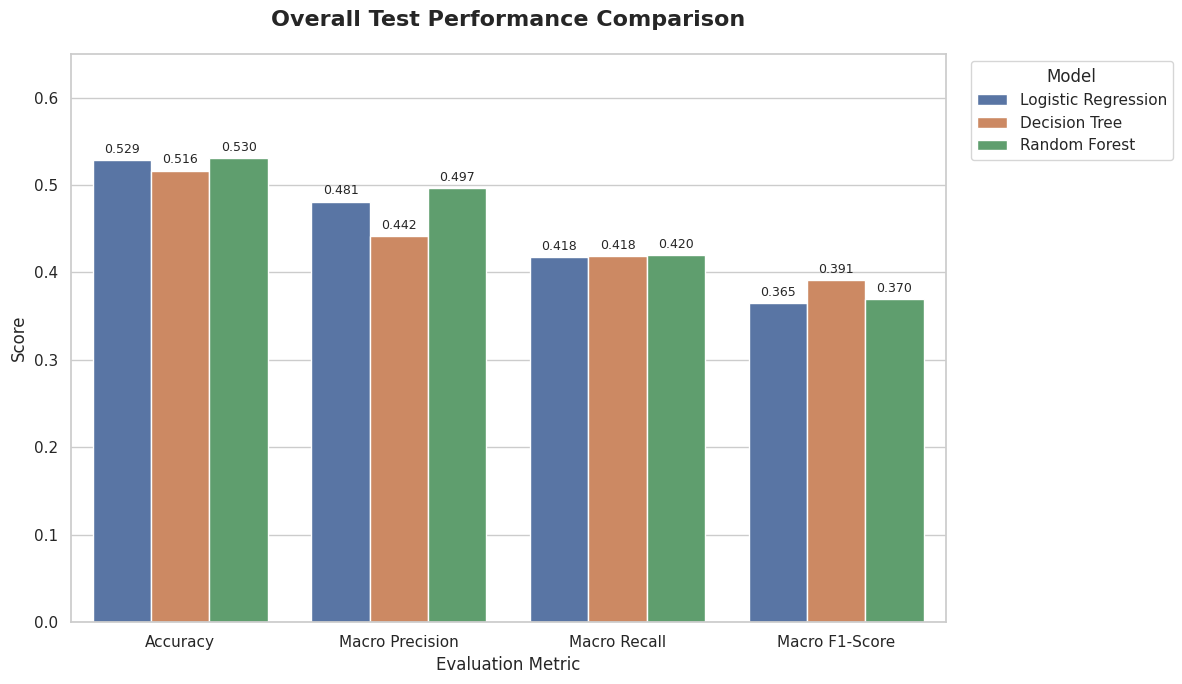

In [73]:
# ============================================================
# PHASE 12.2: VISUALISE OVERALL MODEL PERFORMANCE
# ============================================================

overall_plot_data = (
    overall_model_comparison
    .reset_index()
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)


plt.figure(
    figsize=(12, 7)
)


ax = sns.barplot(
    data=overall_plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    hue_order=MODEL_ORDER,
    palette=MODEL_COLORS
)


plt.title(
    "Overall Test Performance Comparison",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12
)

plt.ylabel(
    "Score",
    fontsize=12
)

plt.ylim(
    0,
    0.65
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )


plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

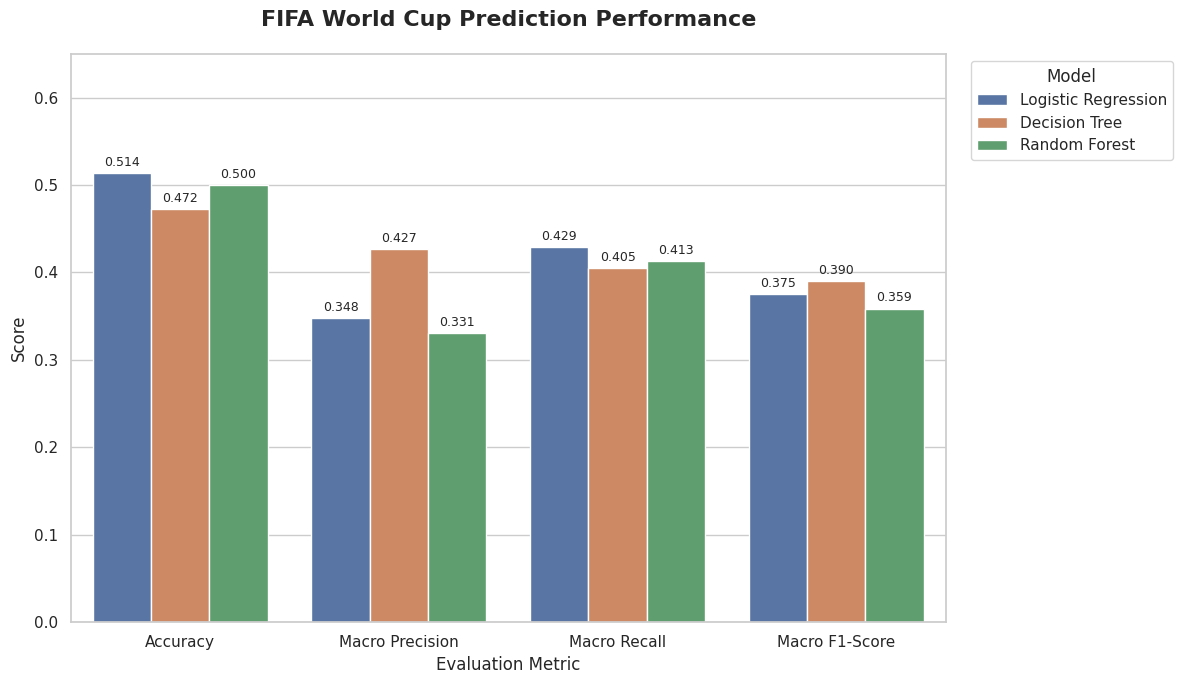

In [74]:
# ============================================================
# PHASE 12.3: VISUALISE FIFA WORLD CUP MODEL PERFORMANCE
# ============================================================

world_cup_plot_data = (
    world_cup_model_comparison
    .reset_index()
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)


plt.figure(
    figsize=(12, 7)
)


ax = sns.barplot(
    data=world_cup_plot_data,
    x="Metric",
    y="Score",
    hue="Model",
    hue_order=MODEL_ORDER,
    palette=MODEL_COLORS
)


plt.title(
    "FIFA World Cup Prediction Performance",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Evaluation Metric",
    fontsize=12
)

plt.ylabel(
    "Score",
    fontsize=12
)

plt.ylim(
    0,
    0.65
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )


plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

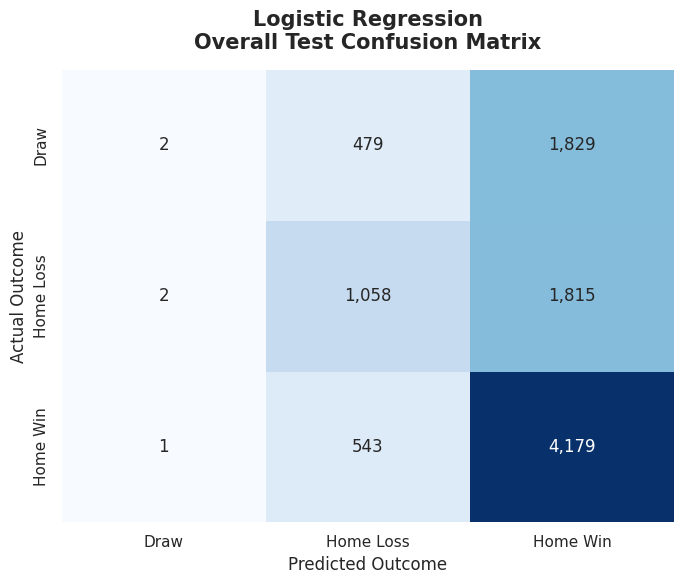

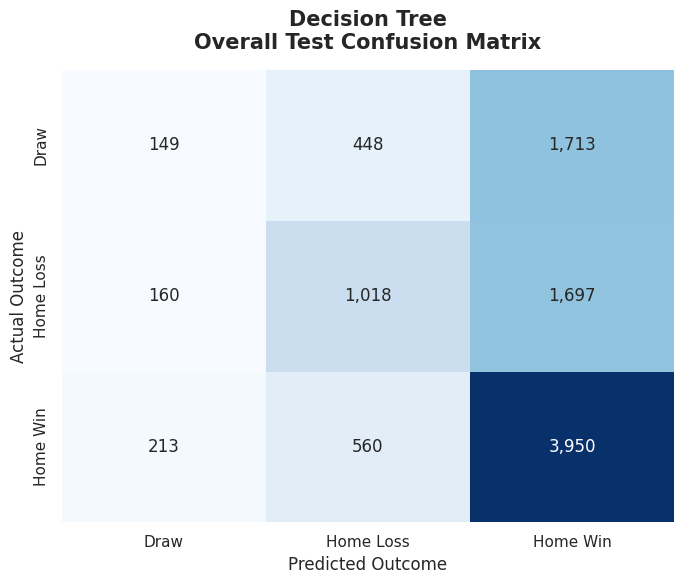

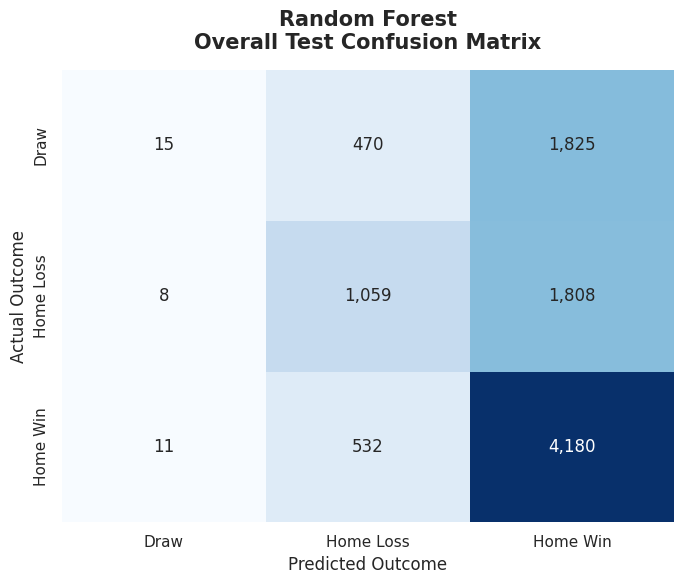

In [75]:
# ============================================================
# PHASE 12.4: VISUALISE OVERALL CONFUSION MATRICES
# ============================================================

for model_name in MODEL_ORDER:

    matrix = (
        overall_confusion_matrices[
            model_name
        ]
    )


    plt.figure(
        figsize=(7, 6)
    )


    sns.heatmap(
        matrix,
        annot=True,
        fmt=",d",
        cmap="Blues",
        xticklabels=CLASS_ORDER,
        yticklabels=CLASS_ORDER,
        cbar=False
    )


    plt.title(
        f"{model_name}\n"
        "Overall Test Confusion Matrix",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.xlabel(
        "Predicted Outcome",
        fontsize=12
    )

    plt.ylabel(
        "Actual Outcome",
        fontsize=12
    )

    plt.tight_layout()

    plt.show()

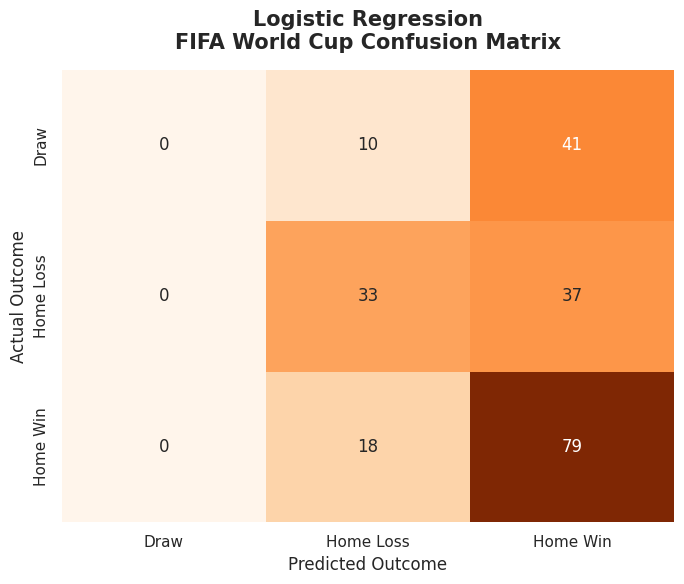

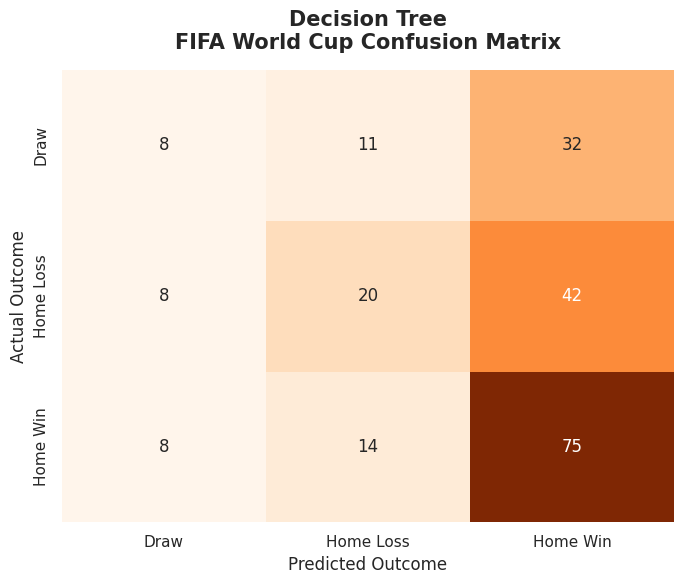

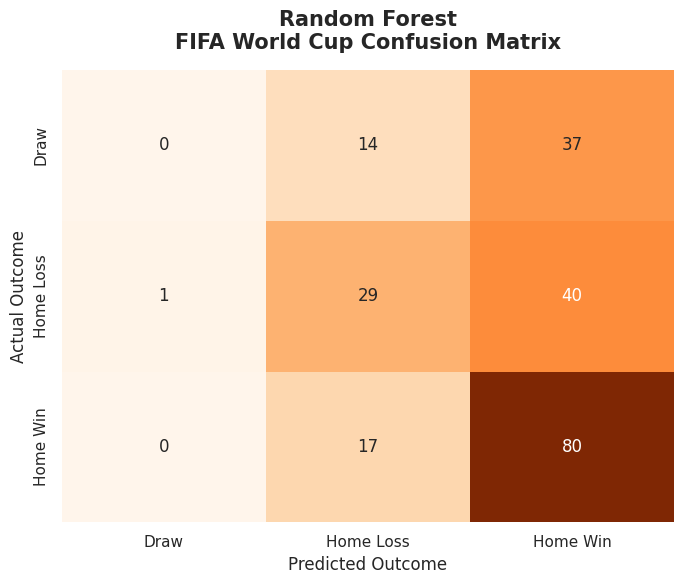

In [76]:
# ============================================================
# PHASE 12.5: VISUALISE FIFA WORLD CUP CONFUSION MATRICES
# ============================================================

for model_name in MODEL_ORDER:

    matrix = (
        world_cup_confusion_matrices[
            model_name
        ]
    )


    plt.figure(
        figsize=(7, 6)
    )


    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Oranges",
        xticklabels=CLASS_ORDER,
        yticklabels=CLASS_ORDER,
        cbar=False
    )


    plt.title(
        f"{model_name}\n"
        "FIFA World Cup Confusion Matrix",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    plt.xlabel(
        "Predicted Outcome",
        fontsize=12
    )

    plt.ylabel(
        "Actual Outcome",
        fontsize=12
    )

    plt.tight_layout()

    plt.show()

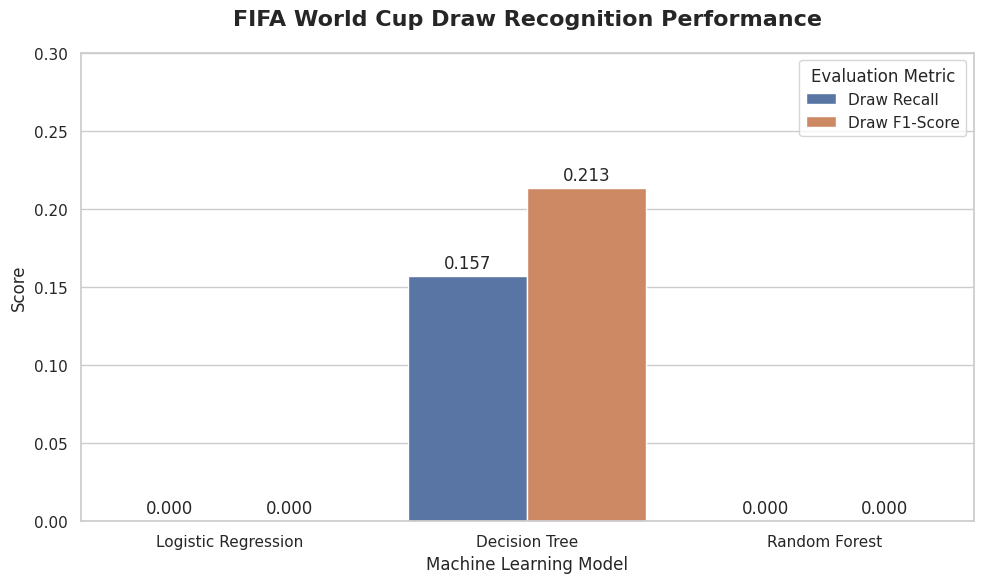

In [77]:
# ============================================================
# PHASE 12.6: VISUALISE DRAW RECOGNITION PERFORMANCE
# ============================================================

draw_plot_data = (
    world_cup_draw_comparison[
        [
            "Draw Recall",
            "Draw F1-Score"
        ]
    ]
    .reset_index()
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)


plt.figure(
    figsize=(10, 6)
)


ax = sns.barplot(
    data=draw_plot_data,
    x="Model",
    y="Score",
    hue="Metric",
    order=MODEL_ORDER
)


plt.title(
    "FIFA World Cup Draw Recognition Performance",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Machine Learning Model",
    fontsize=12
)

plt.ylabel(
    "Score",
    fontsize=12
)

plt.ylim(
    0,
    0.30
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )


plt.legend(
    title="Evaluation Metric"
)

plt.tight_layout()

plt.show()

**Q6 VISUALISATIONS**

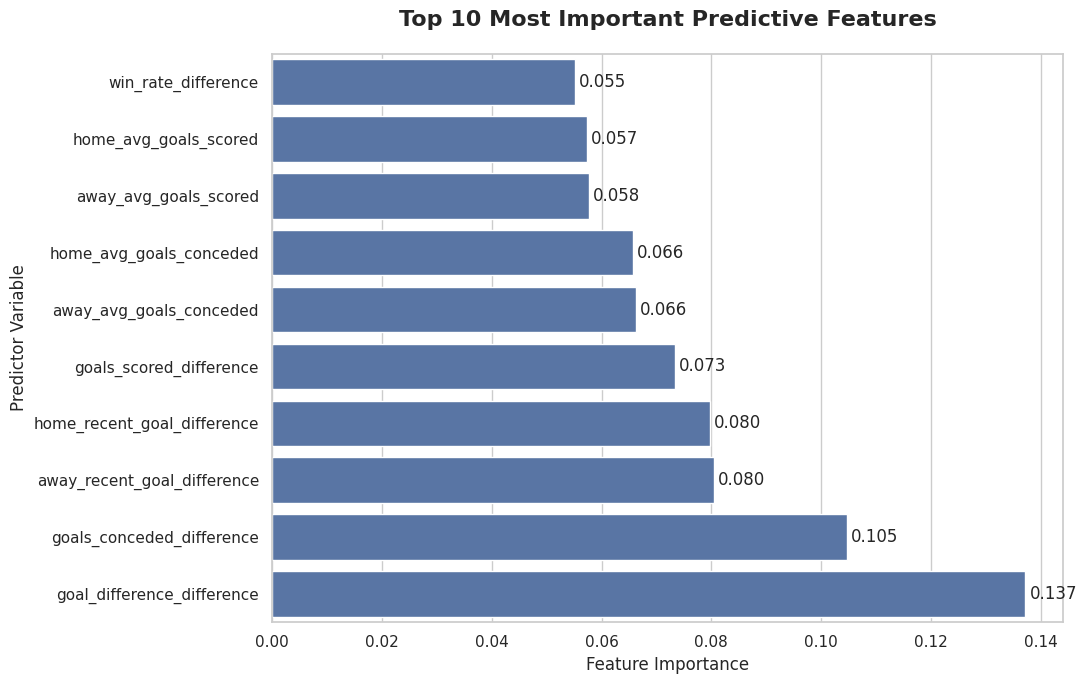

In [78]:
# ============================================================
# PHASE 12.7: VISUALISE RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

top_feature_importance = (
    rf_feature_importance
    .head(10)
    .sort_values(
        by="Importance",
        ascending=True
    )
)


plt.figure(
    figsize=(11, 7)
)


ax = sns.barplot(
    data=top_feature_importance,
    x="Importance",
    y="Feature"
)


plt.title(
    "Top 10 Most Important Predictive Features",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Feature Importance",
    fontsize=12
)

plt.ylabel(
    "Predictor Variable",
    fontsize=12
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )


plt.tight_layout()

plt.show()

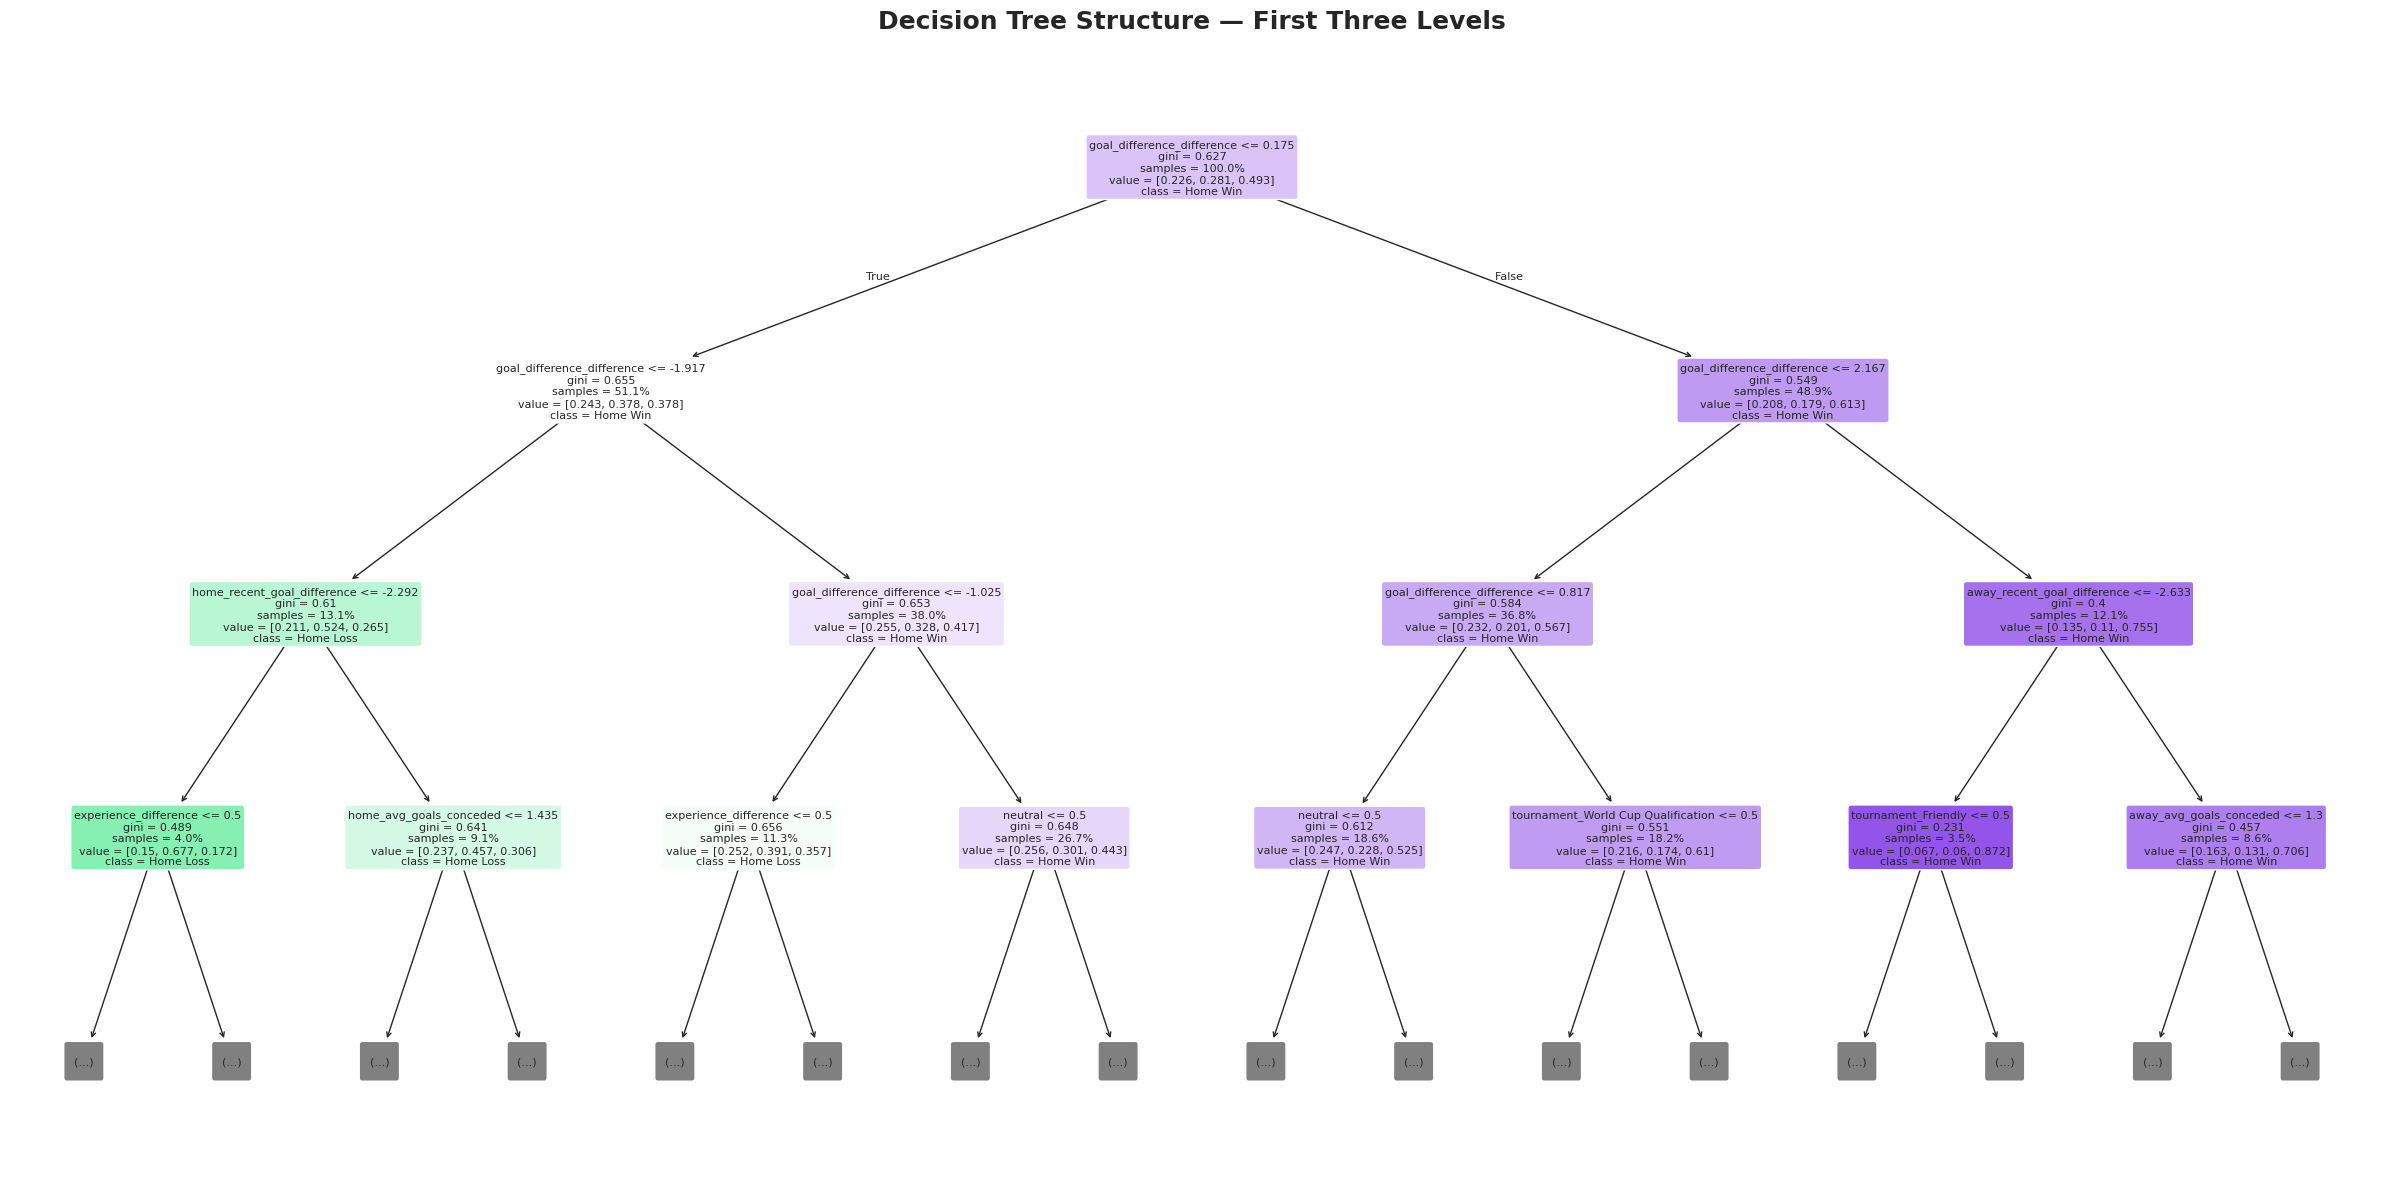

In [79]:
# ============================================================
# PHASE 12.8: VISUALISE DECISION TREE STRUCTURE
# ============================================================

plt.figure(
    figsize=(24, 12)
)


plot_tree(
    decision_tree_model,
    feature_names=feature_columns,
    class_names=decision_tree_model.classes_,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=True
)


plt.title(
    "Decision Tree Structure — First Three Levels",
    fontsize=18,
    fontweight="bold",
    pad=20
)


plt.tight_layout()

plt.show()

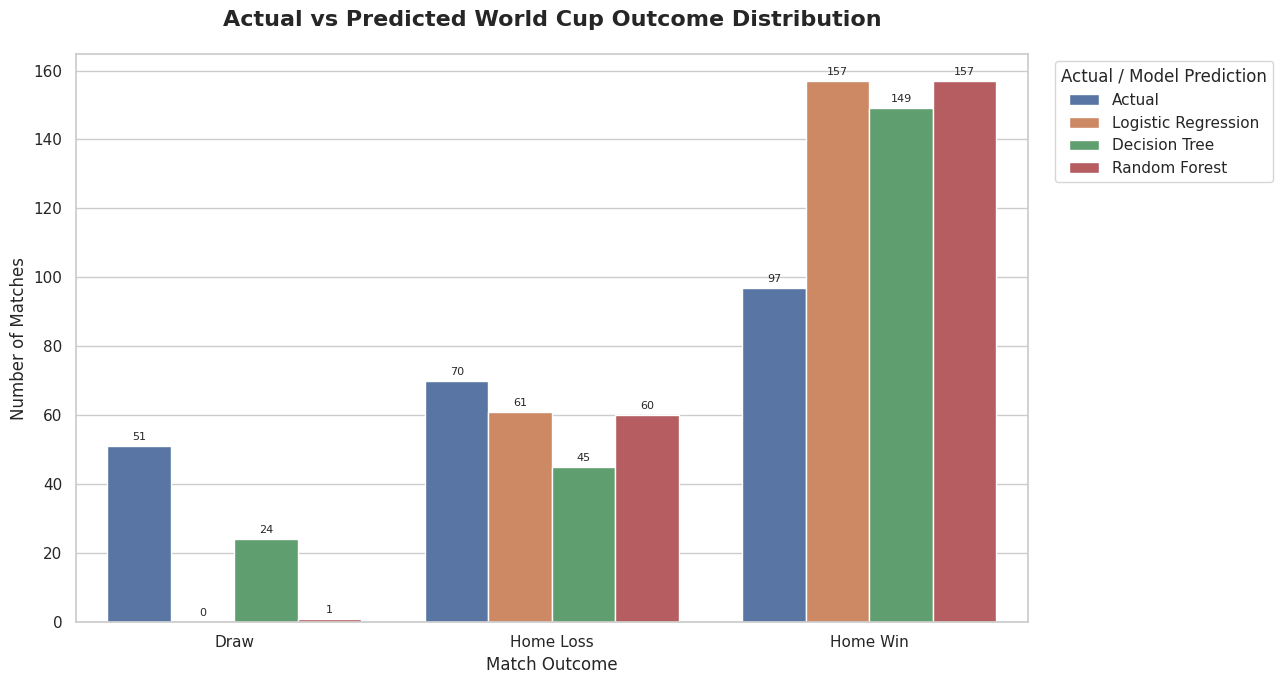

In [80]:
# ============================================================
# PHASE 12.9: VISUALISE ACTUAL VS PREDICTED CLASS DISTRIBUTION
# ============================================================

actual_distribution = (
    pd.Series(y_test_world_cup)
    .value_counts()
    .reindex(CLASS_ORDER)
)


distribution_records = []


for outcome_class in CLASS_ORDER:

    distribution_records.append({
        "Outcome": outcome_class,
        "Source": "Actual",
        "Number of Matches":
            actual_distribution[
                outcome_class
            ]
    })


for model_name, predictions in (
    world_cup_predictions.items()
):

    predicted_distribution = (
        pd.Series(predictions)
        .value_counts()
        .reindex(
            CLASS_ORDER,
            fill_value=0
        )
    )


    for outcome_class in CLASS_ORDER:

        distribution_records.append({
            "Outcome": outcome_class,
            "Source": model_name,
            "Number of Matches":
                predicted_distribution[
                    outcome_class
                ]
        })


class_distribution_comparison = pd.DataFrame(
    distribution_records
)


plt.figure(
    figsize=(13, 7)
)


ax = sns.barplot(
    data=class_distribution_comparison,
    x="Outcome",
    y="Number of Matches",
    hue="Source"
)


plt.title(
    "Actual vs Predicted World Cup Outcome Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Match Outcome",
    fontsize=12
)

plt.ylabel(
    "Number of Matches",
    fontsize=12
)


for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=8
    )


plt.legend(
    title="Actual / Model Prediction",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)


plt.tight_layout()

plt.show()

In [81]:
# ============================================================
# PHASE 12.10: CREATE VISUALISATION SUMMARY
# ============================================================

visualisation_summary = pd.DataFrame({
    "Phase": [
        "12.2",
        "12.3",
        "12.4",
        "12.5",
        "12.6",
        "12.7",
        "12.8",
        "12.9"
    ],

    "Visualisation": [
        "Overall Model Performance",
        "World Cup Model Performance",
        "Overall Confusion Matrices",
        "World Cup Confusion Matrices",
        "Draw Recognition Performance",
        "Random Forest Feature Importance",
        "Decision Tree Structure",
        "Actual vs Predicted Distribution"
    ],

    "Primary Assignment Section": [
        "Q5 Results",
        "Q5 Results",
        "Q5 Results",
        "Q5 Results",
        "Q5 Results",
        "Q6 Discussion",
        "Q6 Discussion",
        "Q6 Discussion"
    ],

    "Recommended for Final Report": [
        "Yes",
        "Yes",
        "Optional",
        "Yes",
        "Yes",
        "Yes",
        "Optional",
        "Yes"
    ]
})


print("VISUALISATION SUMMARY")
print("-" * 80)

display(
    visualisation_summary
)

VISUALISATION SUMMARY
--------------------------------------------------------------------------------


,Phase,Visualisation,Primary Assignment Section,Recommended for Final Report
0,12.2,Overall Model Performance,Q5 Results,Yes
1,12.3,World Cup Model Performance,Q5 Results,Yes
2,12.4,Overall Confusion Matrices,Q5 Results,Optional
3,12.5,World Cup Confusion Matrices,Q5 Results,Yes
4,12.6,Draw Recognition Performance,Q5 Results,Yes
5,12.7,Random Forest Feature Importance,Q6 Discussion,Yes
6,12.8,Decision Tree Structure,Q6 Discussion,Optional
7,12.9,Actual vs Predicted Distribution,Q6 Discussion,Yes


# **PHASE 13 : FINAL FIFA WORLD CUP MATCH PREDICTION**

In [82]:
# ============================================================
# PHASE 13.1: RETRAIN FINAL MODEL ON FULL DATASET
# ============================================================

print("=" * 70)
print("RETRAINING FINAL MODEL FOR DYNAMIC INFERENCE")
print("=" * 70)

# 使用所有带有合法特征的比赛记录进行训练
X_final_train = model_data[feature_columns].copy()
y_final_train = model_data["result"].copy()

# 实例化最终模型 (使用你在 Phase 11 中选出的最佳模型参数)
final_decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=RANDOM_STATE
)

final_decision_tree_model.fit(X_final_train, y_final_train)

print(f"Final Model retrained successfully on all {len(X_final_train):,} historical matches.")

RETRAINING FINAL MODEL FOR DYNAMIC INFERENCE
Final Model retrained successfully on all 49,495 historical matches.


In [83]:
# ============================================================
# PHASE 13.2: DEFINE DYNAMIC FEATURE EXTRACTION LOGIC
# ============================================================

def get_team_latest_history(team_name, full_timeline):
    """
    从带有特征计算的完整时间线数据集中，提取该队伍最后一次出场时的特征状态。
    """
    team_matches = full_timeline[
        (full_timeline["home_team"] == team_name) |
        (full_timeline["away_team"] == team_name)
    ]

    if len(team_matches) == 0:
        return None

    latest_match = team_matches.iloc[-1]

    # 根据该队伍在最后一场比赛中是主队还是客队，提取对应的特征
    if latest_match["home_team"] == team_name:
        return {
            "win_rate": latest_match["home_recent_win_rate"],
            "draw_rate": latest_match["home_recent_draw_rate"],
            "goals_scored": latest_match["home_avg_goals_scored"],
            "goals_conceded": latest_match["home_avg_goals_conceded"],
            "goal_diff": latest_match["home_recent_goal_difference"],
            "exp": latest_match["home_matches_available"]
        }
    else:
        return {
            "win_rate": latest_match["away_recent_win_rate"],
            "draw_rate": latest_match["away_recent_draw_rate"],
            "goals_scored": latest_match["away_avg_goals_scored"],
            "goals_conceded": latest_match["away_avg_goals_conceded"],
            "goal_diff": latest_match["away_recent_goal_difference"],
            "exp": latest_match["away_matches_available"]
        }

print("Dynamic feature extraction function initialized.")

Dynamic feature extraction function initialized.


In [84]:
# ============================================================
# PHASE 13.3: INTERACTIVE MATCH INPUT & FEATURE CONSTRUCTION
# ============================================================

print("=" * 70)
print("INTERACTIVE FIFA MATCH PREDICTION")
print("=" * 70)

home_team = input("Enter Home Team (e.g., Argentina, France): ").strip()
away_team = input("Enter Away Team (e.g., Brazil, Morocco): ").strip()
host_country = input("Enter Host Country (e.g., USA, Qatar): ").strip()

tournament = input(
    "Enter Tournament "
    "(Friendly / FIFA World Cup / FIFA World Cup qualification / Other Competitive): "
).strip()

neutral = int(home_team != host_country)

print("\nMATCH INFORMATION")
print("-" * 70)
print(f"Home Team    : {home_team}")
print(f"Away Team    : {away_team}")
print(f"Host Country : {host_country}")
print(f"Tournament   : {tournament}")
print(f"Neutral      : {neutral}")

# 提取两队最新历史特征
home_hist = get_team_latest_history(home_team, featured_data)
away_hist = get_team_latest_history(away_team, featured_data)

# 冷启动处理（如果队伍没有历史数据，使用全局均值兜底）
def fallback_if_none(hist_dict):
    if hist_dict is None:
        return {
            "win_rate": cold_start_fill_values["home_recent_win_rate"],
            "draw_rate": cold_start_fill_values["home_recent_draw_rate"],
            "goals_scored": cold_start_fill_values["home_avg_goals_scored"],
            "goals_conceded": cold_start_fill_values["home_avg_goals_conceded"],
            "goal_diff": cold_start_fill_values["home_recent_goal_difference"],
            "exp": 0
        }
    return hist_dict

home_features_dict = fallback_if_none(home_hist)
away_features_dict = fallback_if_none(away_hist)

# 构建当前动态对阵的数据行
dynamic_row = pd.DataFrame([{
    "home_recent_win_rate": home_features_dict["win_rate"],
    "away_recent_win_rate": away_features_dict["win_rate"],
    "home_recent_draw_rate": home_features_dict["draw_rate"],
    "away_recent_draw_rate": away_features_dict["draw_rate"],
    "home_avg_goals_scored": home_features_dict["goals_scored"],
    "away_avg_goals_scored": away_features_dict["goals_scored"],
    "home_avg_goals_conceded": home_features_dict["goals_conceded"],
    "away_avg_goals_conceded": away_features_dict["goals_conceded"],
    "home_recent_goal_difference": home_features_dict["goal_diff"],
    "away_recent_goal_difference": away_features_dict["goal_diff"],
    "home_matches_available": home_features_dict["exp"],
    "away_matches_available": away_features_dict["exp"],
    "neutral": neutral
}])

# 添加你在 Phase 6 中定义的差异特征
dynamic_row = add_difference_features(dynamic_row)

# 映射当前赛制的 One-Hot Dummy 变量
tourn_cat = categorize_tournament(tournament)
for col in tournament_dummy_columns:
    dynamic_row[col] = 1 if col == f"tournament_{tourn_cat}" else 0

# 严格按 Phase 6 定义的 feature_columns 顺序对齐列
X_dynamic = dynamic_row[feature_columns].copy()

print("\nDynamic feature matrix successfully constructed and ready for prediction.")

INTERACTIVE FIFA MATCH PREDICTION
Enter Home Team (e.g., Argentina, France): Spain
Enter Away Team (e.g., Brazil, Morocco): Argentina
Enter Host Country (e.g., USA, Qatar): USA
Enter Tournament (Friendly / FIFA World Cup / FIFA World Cup qualification / Other Competitive): FIFA World Cup

MATCH INFORMATION
----------------------------------------------------------------------
Home Team    : Spain
Away Team    : Argentina
Host Country : USA
Tournament   : FIFA World Cup
Neutral      : 1

Dynamic feature matrix successfully constructed and ready for prediction.


In [85]:
# ============================================================
# PHASE 13.4: DYNAMIC MODEL INFERENCE & PROBABILITY OUTPUT
# ============================================================

# 推理预测标签和概率
dynamic_pred = final_decision_tree_model.predict(X_dynamic)[0]
dynamic_proba = final_decision_tree_model.predict_proba(X_dynamic)[0]

# 将概率映射到具体的类别名称
classes = final_decision_tree_model.classes_
prob_dict = {classes[i]: dynamic_proba[i] for i in range(len(classes))}

print("\n" + "="*50)
print("             PREDICTION RESULTS            ")
print("="*50)
print(f"Match        : {home_team} vs {away_team}")
print(f"Host         : {host_country}")
print(f"Tournament   : {tournament} (Category: {tourn_cat})")
print("-" * 50)
print(f"Predicted Outcome (Home Perspective): **{dynamic_pred}**")
print(f"Confidence Level : {max(dynamic_proba)*100:.2f}%")
print("-" * 50)
print("Probability Distribution:")
for outcome, p in prob_dict.items():
    print(f" - {outcome:<10} : {p*100:.2f}%")
print("=" * 50)


             PREDICTION RESULTS            
Match        : Spain vs Argentina
Host         : USA
Tournament   : FIFA World Cup (Category: World Cup)
--------------------------------------------------
Predicted Outcome (Home Perspective): **Home Win**
Confidence Level : 50.00%
--------------------------------------------------
Probability Distribution:
 - Draw       : 40.00%
 - Home Loss  : 10.00%
 - Home Win   : 50.00%


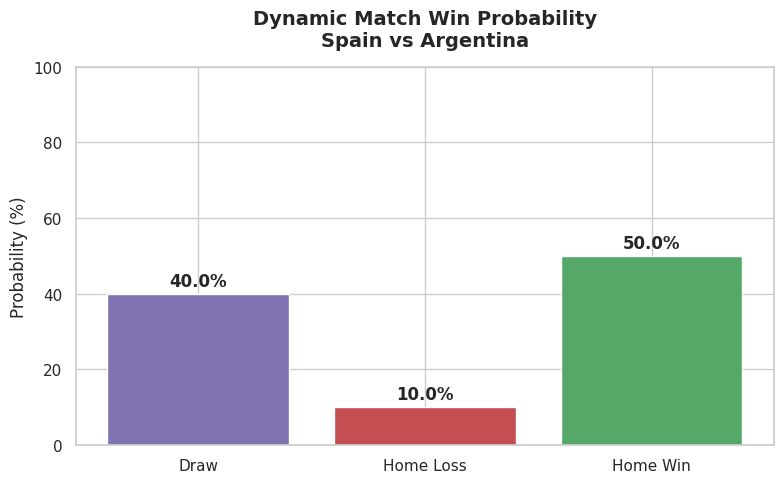

In [86]:
# ============================================================
# PHASE 13.5: VISUALISE DYNAMIC MATCH PREDICTION
# ============================================================

plt.figure(figsize=(8, 5))

# 保持与之前全局设置一致的颜色映射
color_map = {'Draw': '#8172B2', 'Home Loss': '#C44E52', 'Home Win': '#55A868'}
bars = plt.bar(
    prob_dict.keys(),
    [v * 100 for v in prob_dict.values()],
    color=[color_map.get(k, '#333333') for k in prob_dict.keys()]
)

plt.title(
    f"Dynamic Match Win Probability\n{home_team} vs {away_team}",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.ylabel("Probability (%)", fontsize=12)
plt.ylim(0, 100)

# 在柱子上添加百分比标签
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.,
        height + 2,
        f"{height:.1f}%",
        ha='center',
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

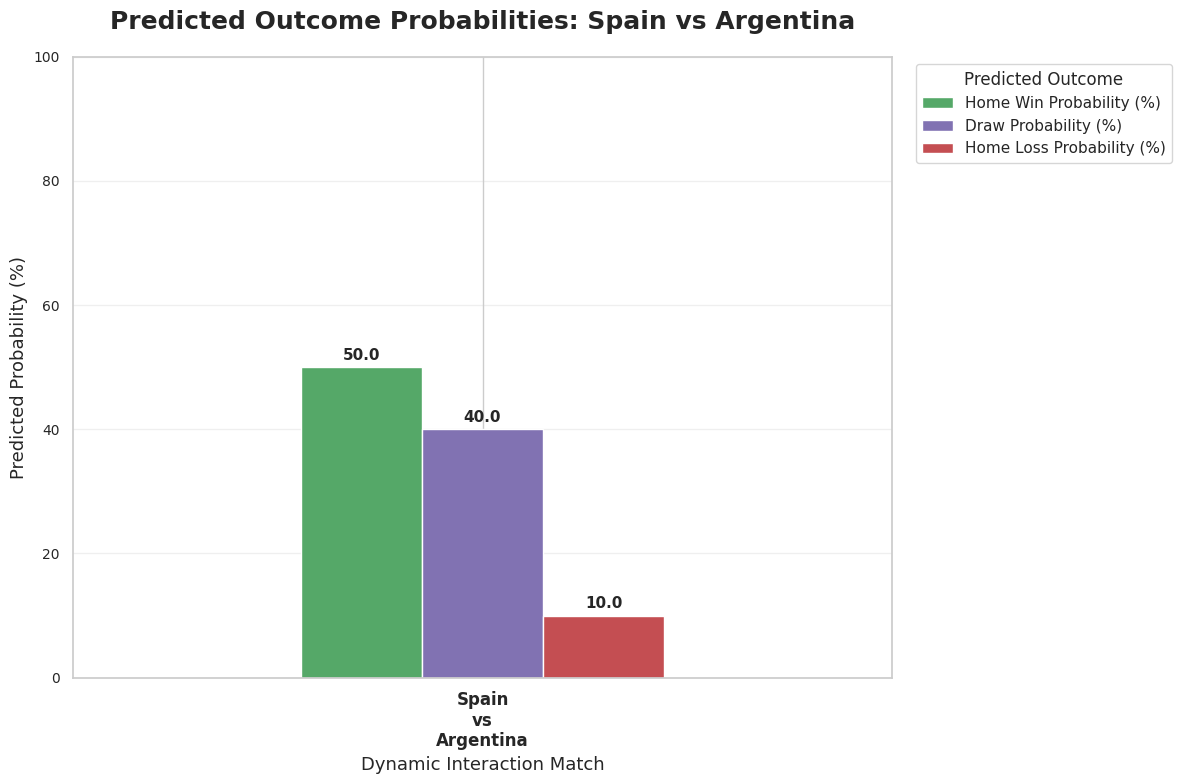

In [87]:
# ============================================================
# PHASE 13.6: VISUALISE DETAILED PREDICTION (PHASE 13.12 STYLE)
# ============================================================

# 将当前动态预测的概率转换为 DataFrame 格式，与原代码 13.12 保持高度一致
dynamic_prob_df = pd.DataFrame({
    "Match": [f"{home_team}\nvs\n{away_team}"],
    "Home Win Probability (%)": [prob_dict.get("Home Win", 0) * 100],
    "Draw Probability (%)": [prob_dict.get("Draw", 0) * 100],
    "Home Loss Probability (%)": [prob_dict.get("Home Loss", 0) * 100]
}).set_index("Match")

# 使用与原 13.12 相同的 Pandas 绘图逻辑 (分组柱状图)
ax = dynamic_prob_df.plot(
    kind="bar",
    figsize=(12, 8),
    width=0.4, # 稍微调窄一点，让单场比赛的柱子不至于太粗
    color=['#55A868', '#8172B2', '#C44E52']
)

plt.title(
    f"Predicted Outcome Probabilities: {home_team} vs {away_team}",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel(
    "Dynamic Interaction Match",
    fontsize=13
)

plt.ylabel(
    "Predicted Probability (%)",
    fontsize=13
)

plt.xticks(
    rotation=0,
    fontsize=12,
    fontweight="bold"
)

plt.yticks(
    fontsize=10
)

plt.ylim(
    0,
    max(
        100,
        dynamic_prob_df.max().max() + 10
    )
)

plt.legend(
    title="Predicted Outcome",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.3
)

# 自动在柱子上打上百分比标签
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3,
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# **PHASE 14 : PROJECT SUMMARY AND REPRODUCIBILITY**

In [88]:
# ============================================================
# PHASE 14.1: SUMMARISE DATASET TRANSFORMATION
# ============================================================

dataset_transformation_summary = pd.DataFrame({
    "Processing Stage": [
        "Original Dataset",
        "Feature-Engineered Dataset",
        "Completed Matches for Modelling",
        "Final Predictor Matrix",
        "Training Set",
        "Testing Set",
        "FIFA World Cup Test Subset",
        "Dynamic Prediction Engine"
    ],
    "Number of Records": [
        len(df),
        len(featured_data),
        len(model_data),
        len(X),
        len(X_train),
        len(X_test),
        len(X_test_world_cup),
        "Infinite (Interactive)"
    ],
    "Purpose": [
        "Raw international football match records",
        "Historical performance features created",
        "Completed matches with known outcomes",
        "Final supervised learning dataset",
        "Chronological model training data",
        "Chronological model testing data",
        "World Cup-specific model evaluation",
        "Real-time match simulation"
    ]
})

print("DATASET TRANSFORMATION SUMMARY")
print("-" * 90)
display(dataset_transformation_summary)

print("\nDATASET FLOW VALIDATION")
print("-" * 90)
completed_plus_future = len(model_data) + len(final_prediction_data)

print(f"Feature-engineered records : {len(featured_data):,}")
print(f"Completed match records    : {len(model_data):,}")
print(f"Unscored historical records: {len(final_prediction_data):,}")
print(f"Completed + Unscored       : {completed_plus_future:,}")

if completed_plus_future == len(featured_data):
    print("\nPASS: All feature-engineered records are accounted for.")
else:
    print("\nWARNING: Dataset record counts require further investigation.")

DATASET TRANSFORMATION SUMMARY
------------------------------------------------------------------------------------------


,Processing Stage,Number of Records,Purpose
0,Original Dataset,49502,Raw international football match records
1,Feature-Engineered Dataset,49502,Historical performance features created
2,Completed Matches for Modelling,49495,Completed matches with known outcomes
3,Final Predictor Matrix,49495,Final supervised learning dataset
4,Training Set,39587,Chronological model training data
5,Testing Set,9908,Chronological model testing data
6,FIFA World Cup Test Subset,218,World Cup-specific model evaluation
7,Dynamic Prediction Engine,Infinite (Interactive),Real-time match simulation



DATASET FLOW VALIDATION
------------------------------------------------------------------------------------------
Feature-engineered records : 49,502
Completed match records    : 49,495
Unscored historical records: 7
Completed + Unscored       : 49,502

PASS: All feature-engineered records are accounted for.


In [89]:
# ============================================================
# PHASE 14.2: SUMMARISE FINAL PREDICTOR FEATURES
# ============================================================

feature_categories = {
    "Recent Performance": [
        "home_recent_win_rate", "away_recent_win_rate",
        "home_recent_draw_rate", "away_recent_draw_rate",
        "home_avg_goals_scored", "away_avg_goals_scored",
        "home_avg_goals_conceded", "away_avg_goals_conceded",
        "home_recent_goal_difference", "away_recent_goal_difference"
    ],
    "Historical Experience": [
        "home_matches_available", "away_matches_available"
    ],
    "Comparative Difference": [
        "win_rate_difference", "draw_rate_difference",
        "goals_scored_difference", "goals_conceded_difference",
        "goal_difference_difference", "experience_difference"
    ],
    "Match Context": [
        "neutral"
    ],
    "Tournament Category": [
        "tournament_Friendly", "tournament_Other Competitive",
        "tournament_World Cup", "tournament_World Cup Qualification"
    ]
}

feature_summary_records = []
for category, category_features in feature_categories.items():
    for feature in category_features:
        feature_summary_records.append({
            "Feature Category": category,
            "Predictor Feature": feature,
            "Included in Final Model": feature in feature_columns
        })

final_feature_summary = pd.DataFrame(feature_summary_records)

print("FINAL PREDICTOR FEATURE SUMMARY")
print("-" * 90)
print(f"Total predictor variables: {len(feature_columns)}")
display(final_feature_summary)

print("\nFEATURE CATEGORY SUMMARY")
print("-" * 90)
feature_category_summary = (
    final_feature_summary.groupby("Feature Category", sort=False)
    .agg(
        Number_of_Features=("Predictor Feature", "count"),
        Features_Included=("Included in Final Model", "sum")
    )
)
display(feature_category_summary)

FINAL PREDICTOR FEATURE SUMMARY
------------------------------------------------------------------------------------------
Total predictor variables: 23


,Feature Category,Predictor Feature,Included in Final Model
0,Recent Performance,home_recent_win_rate,True
1,Recent Performance,away_recent_win_rate,True
2,Recent Performance,home_recent_draw_rate,True
3,Recent Performance,away_recent_draw_rate,True
4,Recent Performance,home_avg_goals_scored,True
5,Recent Performance,away_avg_goals_scored,True
6,Recent Performance,home_avg_goals_conceded,True
7,Recent Performance,away_avg_goals_conceded,True
8,Recent Performance,home_recent_goal_difference,True
9,Recent Performance,away_recent_goal_difference,True



FEATURE CATEGORY SUMMARY
------------------------------------------------------------------------------------------


,Number_of_Features,Features_Included
Feature Category,,
Recent Performance,10,10
Historical Experience,2,2
Comparative Difference,6,6
Match Context,1,1
Tournament Category,4,4


In [90]:
# ============================================================
# PHASE 14.3: SUMMARISE MODEL EVALUATION RESULTS
# ============================================================

overall_summary = overall_model_comparison.copy().reset_index()
overall_summary["Evaluation Dataset"] = "Overall Test Set"

world_cup_summary = world_cup_model_comparison.copy().reset_index()
world_cup_summary["Evaluation Dataset"] = "FIFA World Cup Test Subset"

final_model_results_summary = pd.concat([overall_summary, world_cup_summary], ignore_index=True)
final_model_results_summary = final_model_results_summary[[
    "Evaluation Dataset", "Model", "Accuracy",
    "Macro Precision", "Macro Recall", "Macro F1-Score"
]]

print("FINAL MODEL EVALUATION RESULTS")
print("-" * 100)
display(final_model_results_summary.round(4))

print("\nMODEL PERFORMANCE LEADERS")
print("-" * 100)
performance_leaders = pd.DataFrame({
    "Evaluation Criterion": [
        "Highest Overall Accuracy", "Highest Overall Macro F1-Score",
        "Highest World Cup Accuracy", "Highest World Cup Macro F1-Score",
        "Best World Cup Draw Recognition"
    ],
    "Model": [
        overall_model_comparison["Accuracy"].idxmax(),
        overall_model_comparison["Macro F1-Score"].idxmax(),
        world_cup_model_comparison["Accuracy"].idxmax(),
        world_cup_model_comparison["Macro F1-Score"].idxmax(),
        world_cup_draw_comparison["Draw F1-Score"].idxmax()
    ]
})
display(performance_leaders)

FINAL MODEL EVALUATION RESULTS
----------------------------------------------------------------------------------------------------


,Evaluation Dataset,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Overall Test Set,Logistic Regression,0.5288,0.4809,0.4179,0.3650
1,Overall Test Set,Decision Tree,0.5165,0.4415,0.4183,0.3915
2,Overall Test Set,Random Forest,0.5303,0.4967,0.4200,0.3696
3,FIFA World Cup Test Subset,Logistic Regression,0.5138,0.3481,0.4286,0.3753
4,FIFA World Cup Test Subset,Decision Tree,0.4725,0.4270,0.4053,0.3903
5,FIFA World Cup Test Subset,Random Forest,0.5000,0.3310,0.4130,0.3587



MODEL PERFORMANCE LEADERS
----------------------------------------------------------------------------------------------------


,Evaluation Criterion,Model
0,Highest Overall Accuracy,Random Forest
1,Highest Overall Macro F1-Score,Decision Tree
2,Highest World Cup Accuracy,Logistic Regression
3,Highest World Cup Macro F1-Score,Decision Tree
4,Best World Cup Draw Recognition,Decision Tree


In [91]:
# ============================================================
# PHASE 14.4: DOCUMENT FINAL MODEL SELECTION
# ============================================================

selected_model_overall_results = overall_model_comparison.loc[best_model_name]
selected_model_world_cup_results = world_cup_model_comparison.loc[best_model_name]
selected_model_draw_results = world_cup_draw_comparison.loc[best_model_name]

final_model_selection_summary = pd.DataFrame({
    "Selection Component": [
        "Selected Final Model",
        "Primary Selection Criterion",
        "Overall Accuracy",
        "Overall Macro F1-Score",
        "World Cup Accuracy",
        "World Cup Macro F1-Score",
        "World Cup Draw Recall",
        "World Cup Draw F1-Score"
    ],
    "Value": [
        best_model_name,
        "Highest FIFA World Cup Macro F1-Score",
        selected_model_overall_results["Accuracy"],
        selected_model_overall_results["Macro F1-Score"],
        selected_model_world_cup_results["Accuracy"],
        selected_model_world_cup_results["Macro F1-Score"],
        selected_model_draw_results["Draw Recall"],
        selected_model_draw_results["Draw F1-Score"]
    ]
})

print("FINAL MODEL SELECTION SUMMARY")
print("-" * 90)
display(final_model_selection_summary)

print("\nFINAL MODEL SELECTION RATIONALE")
print("-" * 90)
print(f"{best_model_name} was selected as the final model because it achieved the highest Macro F1-Score on the FIFA World Cup test subset.")
print("\nMacro F1-Score was prioritised over accuracy because the prediction task contains three unequally distributed outcome classes: Draw, Home Loss, and Home Win.")
print(f"\nThe selected {best_model_name} was retrained using all completed matches to serve as the core engine for the Dynamic Interactive Prediction System.")

FINAL MODEL SELECTION SUMMARY
------------------------------------------------------------------------------------------


,Selection Component,Value
0,Selected Final Model,Decision Tree
1,Primary Selection Criterion,Highest FIFA World Cup Macro F1-Score
2,Overall Accuracy,0.516451
3,Overall Macro F1-Score,0.391488
4,World Cup Accuracy,0.472477
5,World Cup Macro F1-Score,0.390305
6,World Cup Draw Recall,0.156863
7,World Cup Draw F1-Score,0.213333



FINAL MODEL SELECTION RATIONALE
------------------------------------------------------------------------------------------
Decision Tree was selected as the final model because it achieved the highest Macro F1-Score on the FIFA World Cup test subset.

Macro F1-Score was prioritised over accuracy because the prediction task contains three unequally distributed outcome classes: Draw, Home Loss, and Home Win.

The selected Decision Tree was retrained using all completed matches to serve as the core engine for the Dynamic Interactive Prediction System.


In [92]:
# ============================================================
# PHASE 14.5: DOCUMENT REPRODUCIBILITY INFORMATION
# ============================================================

reproducibility_summary = pd.DataFrame({
    "Reproducibility Component": [
        "Random State",
        "Data Split Strategy",
        "Training Proportion",
        "Historical Feature Window",
        "Target Classes",
        "Number of Predictors",
        "Final Deployment Engine",
        "Future Matches Predicted",
        "Temporal Leakage Prevention"
    ],
    "Configuration": [
        RANDOM_STATE,
        "Chronological train-test split",
        "80%",
        f"Previous {RECENT_MATCH_WINDOW} matches",
        "Draw / Home Loss / Home Win",
        len(feature_columns),
        f"Dynamic Interactive {best_model_name}",
        "Infinite (User-defined inputs)",
        "Historical features use only matches played before each target match"
    ]
})

print("PROJECT REPRODUCIBILITY INFORMATION")
print("-" * 100)
display(reproducibility_summary)

print("\nREPRODUCIBILITY VALIDATION")
print("-" * 100)

latest_training_date = train_metadata["date"].max()
earliest_testing_date = test_metadata["date"].min()

if latest_training_date < earliest_testing_date:
    print("PASS: Strict temporal separation between training and testing data confirmed.")
else:
    print("WARNING: Temporal split requires further investigation.")

print("\nHistorical feature engineering was performed using only information available before each match.")
print("\nPROJECT PIPELINE COMPLETED SUCCESSFULLY.")

PROJECT REPRODUCIBILITY INFORMATION
----------------------------------------------------------------------------------------------------


,Reproducibility Component,Configuration
0,Random State,42
1,Data Split Strategy,Chronological train-test split
2,Training Proportion,80%
3,Historical Feature Window,Previous 5 matches
4,Target Classes,Draw / Home Loss / Home Win
5,Number of Predictors,23
6,Final Deployment Engine,Dynamic Interactive Decision Tree
7,Future Matches Predicted,Infinite (User-defined inputs)
8,Temporal Leakage Prevention,Historical features use only matches played be...



REPRODUCIBILITY VALIDATION
----------------------------------------------------------------------------------------------------
PASS: Strict temporal separation between training and testing data confirmed.

Historical feature engineering was performed using only information available before each match.

PROJECT PIPELINE COMPLETED SUCCESSFULLY.
